# PROJET TIM: COULEUR

*Arrigoni Ambroise, Benslimane Sarah, Douagi Selma & Sourdrille Nathan*

Ce projet s'intéresse à la segmentation d'images couleur par l'algorithme SLIC.

## Principe de SLIC

Le **clustering itératif linéaire simple (SLIC) est une méthode de segmentation d'images utilisée pour générée des superpixels**. Cette méthode est née du constat que les différentes méthodes existantes de découpage en superpixels n'étaient pas entièrement satisfaisantes. En effet, un très bon algorithme de segmentation en superpixels exige que les superpixels épousent correctement les contours de l'image, il doit être rapide et économe en mémoire.  
Dès lors, l'algorithme SLIC adopte une approche de clustering de type k-means afin de produire effiacement des superpixels compacts, réguliers et adaptés à la structure de l'image. Il s'agit de la méthode la plus intéressante pour la génération de superpixels car son implémentation permet une exécution rapide, qui consomme peu de mémoire, son utilisation est simple et  peut s'étendre ensuite facilement ensuite à d'autres notions comme les supervoxels. Le principe même de SLIC est d'exploiter la redondance spatiale et colorimétrique des images.

Pour continuer, un superpixel correspond à un groupe de pixels voisins qui sont similaires en couleur et proche dans le plan spatial. Autrement dit, on associe des pixels entre eux car ils sont de la même couleur (ou presque) et voisins. Il y a donc deux notions à prendre en compte: la localisation spatiale du pixel et sa couleur. 

## Premiers pas vers l'algorithme

### Librairies utilisées

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import time
from skimage.segmentation import slic, mark_boundaries

from skimage import io
from scipy.ndimage import gaussian_gradient_magnitude
from scipy import ndimage
from skimage.color import rgb2lab
from typing import Tuple, Optional, Dict, Any

### Chargement de l'image 

Tout d'abord, il nous faut choisir une image d'étude. On se pose comme objectif de parvenir à segmenter en superpixels l'image *fleur.jpg*. D'autres images seront utilisées ensuite pour expliquer et tester le fonctionnement de notre algorithme.

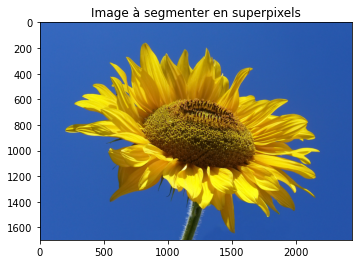

In [2]:
path_images = '../Images_Projet/'
img = cv2.imread(path_images+'fleur.jpg',1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb )
plt.title("Image à segmenter en superpixels")
plt.show()

Pour comparer ou regrouper des couleurs, avec SLIC notamment, l'espace couleur CIELAB est beaucoup plus fiable que RGB. Il s'agit d'un espace de couleur perceptuellement uniforme, c'est à dire que la distance entre deux couleurs en Lab correspond approximativement à ce que l'oeil voit comme différence de couleur.  
3 canaux:  
- L: Luminosité; intervalle: [0,100]; 0: noir, 100: blanc
- a: Axe vert/rouge; négatif: vert, positif: rouge
- b: Axe bleu/jaune; négatif: bleu, positif: jaune

On le verra par la suite quand on s'interessera au détail de l'algorithme SLIC, mais une première implémentation que nous avons mis en place nécessitait des temps de calculs très longs, trop longs. Et ce temps de calcul est directement proportionnel au nombre de pixels de l'image. C'est pourquoi, nous avons décidé de réduire la taille de notre image à 500\*500 pixels, car le temps de calcul pour notre image de base de 1700\*2400 pixel était tout simplement exorbitant. Il s'agit bien évidemment d'une solution qui n'est pas envisageable puisqu'on ne peut pas se restreindre simplement à diminuer la taille d'une image qu'on souhaite segmenter en superpixels mais c'était une étape nécessaire pour développer un algorithme satisfaisant ensuite.

In [3]:
img_rgb_resized = cv2.resize(img_rgb, (500,500))
img_lab = cv2.cvtColor(img_rgb_resized, cv2.COLOR_BGR2LAB).astype(np.float64)

Pour continuer, l'algorithme SLIC repose sur les centroïdes.  
**Un centroïde représente un superpixel en formation durant l'algorithme. Avant l'exécution de SLIC, c'est un pixel. A la fin, il représente tout le superpixel, sa position est la moyenne des positions de tous les pixels du superpixel, sa couleur est la moyenne des couleurs Lab de tous les pixels du superpixel.**  
Il contient 5 dimensions: \[(x,y),(L,a,b)\]:
- (x,y): position spatiale
- (L,a,b): couleur  


Ils servent de points de référence pour construire les superpixels. Sans centroïde, on ne saut pas ou commencer les superpixels ni comment les regrouper en pixels.

Étapes d'initialisation de l'algorithme:  
1. Choisir le nombre de superpixels $K$  
2. Calculer la taille approximative de chaque superpixel $S$ :  

$
S = \sqrt{\frac{N}{K}}
$;   $N$: nombre total de pixels dans l’image.  

3. Placer les centroïdes initiaux sur une grille régulière espacée de $S$ pixels. Cela assure que les superpixels aient à peu près tous la même taille.
4. Ajuster la position des centroïdes vers un minimum de gradient local pour éviter qu’ils ne tombent sur des bords forts.

Un superpixel doit:
- regrouper les pixels similaires en couleur (Lab)
- être compact spatialement (c'est à dire que les pixels doivent être proches).

Donc si deux pixels sont identiques en couleurs mais très éloignées, on ne remplit pas le second critère donc on ne les rassemble pas dans un même centroïde. Idem, si deux pixels sont voisins mais de couleurs opposés, on ne les rassemble pas dans le même centroïde. C'est ce que calcule compute_distance qui prend en compte ces deux critères.

In [4]:
# nombre de superpixels (seul paramètre)
K = 40
# calcul de la taille approximative de chaque superpixel
H,W = img_lab.shape[:2]
N = H*W
S = int(np.sqrt(N/K))
print(f'Taille de chaque superpixel: {S} pixels')

Taille de chaque superpixel: 79 pixels


In [5]:
centroids = []
for i in range(S//2, H, S):
    for j in range(S//2, W, S):
        L, a, b = img_lab[i,j]
        centroids.append([L,a,b,i,j])
centroids = np.array(centroids)

D (distance): permet de mesurer le centroïde le plus proche de chaque pixel. D combine la distance colorimétrique dans l'espace CIELAB et la distance spatiale dans le plan de l'image.  
m (poids de la compacité): équilibre couleur/ distance spatiale.

In [6]:
# basé sur la formule (1) du papier 
def compute_distance(pixel, centroid, S, m):
    
    pixel_lab = pixel[:3]
    centroid_lab = centroid[:3]
    pixel_pos = pixel[3:5]
    centroid_pos = centroid[3:5]

    dc = np.linalg.norm(pixel_lab - centroid_lab) # distance colorimétrique
    ds = np.linalg.norm(pixel_pos - centroid_pos) # distance spatiale
    
    # Ns = S; Nc = m
    D = np.sqrt((dc/m)**2 + (ds/S)**2) # prise en compte des deux types de distances
    
    return D

On doit assigner chaque superpixel à un centroïde.  
Chaque pixel de l’image regarde les centroïdes proches et choisit celui pour lequel la distance combinée couleur + position est minimale. Cependant le pixel ne regarde que les centroïdes qui sont dans une fenêtre 2S\*2S. C'est cette fenêtre, qui sert de filtrage spatial localisé, qui permet à SLIC d'être beaucoup plus rapide que le k-means standard, dans lequel chaque pixel doit être comparé à tous les centres de clusters. Il s'agit d'une optimisation possible uniquement grâce à la mesure de D. 

L'algorithme va également implémenter un calcul de gradient car on ne souhaite pas que les centroïdes qu'on a initalisés tombent directement sur des contours donc on cherche le pixel avec le plus petit gradient dans une fenêtre autour de la position intiiale du centroïde et on déplace le centroïde vers ce pixel.

Gradient d'un pixel: combien la couleur change par rapport à ses voisins.
- gradient faible => zone homogène (même couleur)
- gradient fort => zone hétérogène (changement de couleur)

## Première implémentation de SLIC

In [7]:
def slic_manual(img_lab, centroids, S, m=10, max_iter=10):

    H, W = img_lab.shape[:2]
    
    gradient = np.sum(gaussian_gradient_magnitude(img_lab, sigma=1), axis=2)

    for idx, c in enumerate(centroids):
        x, y = int(round(c[3])), int(round(c[4]))
        x_min = max(x - 1, 0) 
        x_max = min(x + 2, H) 
        y_min = max(y - 1, 0) 
        y_max = min(y + 2, W)
        window = gradient[x_min:x_max, y_min:y_max]
        min_idx = np.unravel_index(np.argmin(window), window.shape)
        centroids[idx, 3] = x_min + min_idx[0] 
        centroids[idx, 4] = y_min + min_idx[1]
    
    labels = -1 * np.ones((H, W), dtype=int)
    distances = np.full((H, W), np.inf)

    # plusieurs itérations pour affiner les superpixels
    for it in range(max_iter):
        print(f"Iteration {it+1}/{max_iter}")
        distances[:] = np.inf  
        
        # on parcout chaque superpixel
        for idx, centroid in enumerate(centroids):
            
            # coordonées du centroïde
            cx = int(round(centroid[3]))  
            cy = int(round(centroid[4]))  
            
            # fenêtre autour du centroïde
            x_min = max(cx - S, 0)
            x_max = min(cx + S, H - 1)
            y_min = max(cy - S, 0)
            y_max = min(cy + S, W - 1)
            
            # pour chaque pixel de la fenêtre on calcule la distance
            for i in range(x_min, x_max + 1):
                for j in range(y_min, y_max + 1):
                    pixel = np.concatenate((img_lab[i, j], [i, j])) 
                    D = compute_distance(pixel, centroid, S, m)
                    if D < distances[i, j]:
                        distances[i, j] = D
                        labels[i, j] = idx
        
        # assignation du pixel à un centroïde plus proche si la
        # distance calculée est plus petite que jusqu'alors
        new_centroids = np.zeros_like(centroids)
        
        # on parcout tous les superpixels
        for k in range(len(centroids)):
            
            # pour chaque superpixel, on créé un masque qui permet
            # de sélectionner les pixels qui lui appartiennent
            mask = (labels == k)
            
            # cela permet de mettre à jour les centroïdes après l'ajout
            # de pixels
            if np.any(mask):
                L_mean = np.mean(img_lab[:, :, 0][mask])
                a_mean = np.mean(img_lab[:, :, 1][mask])
                b_mean = np.mean(img_lab[:, :, 2][mask])
                coords = np.argwhere(mask)
                x_mean = np.mean(coords[:, 0])
                y_mean = np.mean(coords[:, 1])
                new_centroids[k] = [L_mean, a_mean, b_mean, x_mean, y_mean]
            else:
                new_centroids[k] = centroids[k]  
        
        # pour la fin de l'algorithme on a deux critères: max_iter; shift
        # shift mesure à quel point tous les centroïdes ont bougé par rapport à la 
        # dernière itération, donc si cette valeur est grande, on continue d'itérer
        shift = np.linalg.norm(new_centroids - centroids)
        print(f"  Déplacement total des centroïdes : {shift:.4f}")
        centroids = new_centroids
        if shift < 1e-4:
            print("  Convergence atteinte.")
            break

    return labels, centroids

L'algorithme précédent possède un gros problème, il s'agit de la boucle imbriquée suivante:

    for i in range(x_min, x_max + 1):
        for j in range(y_min, y_max + 1):

En effet, le parcours de l'ensemble des pixels de l'image, plusieurs fois (car on a plusieurs itérations (10 itérations sont conseillées par le papier)), fait exploser les temps de calcul de l'algorithme. C'est ainsi pourquoi on avait réduit la taille de l'image préalablement. Dès lors, on va pouvoir mettre en place plus tard une seconde implémentation beaucoup plus rapide et pratique, qui accepte tout type et taille d'image.

In [8]:
# permet de calculer le temps de calcul d'une fonction
def chronometrer(fonction, fonction_name, *args_fonction):
    t_before = time.time()
    output = fonction(*args_fonction)
    t_after = time.time()
    print("Temps d'exécution de {0} : {1:.2f} sec".format(fonction_name,t_after-t_before))
    return output

In [9]:
# exécution de l'algorithme "slic_manual" sur notre image "fleur.jpg", de taille réduite
labels, centroids = chronometrer(
    slic_manual,
    "SLIC manuel",
    img_lab,    
    centroids,  
    S,          
    10,         
    6          
)

Iteration 1/6
  Déplacement total des centroïdes : 147.1355
Iteration 2/6
  Déplacement total des centroïdes : 94.1540
Iteration 3/6
  Déplacement total des centroïdes : 79.0295
Iteration 4/6
  Déplacement total des centroïdes : 54.1877
Iteration 5/6
  Déplacement total des centroïdes : 45.3500
Iteration 6/6
  Déplacement total des centroïdes : 35.9594
Temps d'exécution de SLIC manuel : 41.66 sec


On observe que le déplacement total des centroïdes s'améliore mais il reste encore assez haut après quelques itérations. On constate également que le temps de calcul est très important donc ce modèle d'algorithme n'est pas viable.

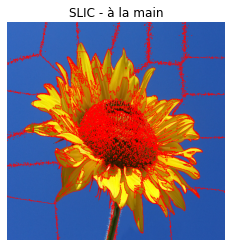

In [10]:
# edges va permettre de construire un masque booléen
# True si le pixel est sur le bord, cad entre deux superpixels
# False si le pixel est à l'intérieur d'un superpixel
# ce sont les pixels True qui apparaissent en rouge sur le plot
edges = np.zeros_like(labels, dtype=bool)
edges[1: , :] |= (labels[1: , :] != labels[:-1, :])
edges[: , 1:] |= (labels[: , 1:] != labels[: , :-1])

img_contour = img_rgb_resized.copy()
img_contour[edges] = [255, 0, 0]
plt.imshow(img_contour)
plt.title("SLIC - à la main")
plt.axis('off')
plt.show()

L'affichage de la segmentation SLIC montre que pour le fond de l'image, c'est à dire la partie bleu, le découpage est plutôt satisfaisant, cependant il n'est absolument pas satisfaisant en ce qui concerne les pétales et le centre du tournesol.

L'algorithme suivant est un algorithme de post-traitement permettant de corriger les défauts restants de SLIC. En effet, à la fin du processus, certains pixels peuvent se retrouver "orphelins": ils ne font partie d'aucun superpiel. Pour corriger ce problème, on va réassigner ces pixels isolés au superpixel le plus proche afin de garantir une connectivité spatiale cohérente.

In [11]:
def enforce_connectivity_fast(labels, min_size_ratio=0.25):
    h, w = labels.shape
    S = int(np.sqrt(h * w / len(np.unique(labels))))
    min_size = int(S**2 * min_size_ratio)

    new_labels = labels.copy()
    structure = np.ones((3, 3), dtype=bool)

    for label in np.unique(labels):
        mask = (labels == label)
        labeled_cc, num_cc = ndimage.label(mask, structure=structure)
        sizes = ndimage.sum(mask, labeled_cc, range(1, num_cc + 1))
        small = np.where(sizes < min_size)[0] + 1
        for s in small:
            region = (labeled_cc == s)
            dilated = ndimage.binary_dilation(region)
            border = dilated & ~region
            neighbor_labels = labels[border]
            if neighbor_labels.size > 0:
                new_labels[region] = np.bincount(neighbor_labels).argmax()
    return new_labels

Temps d'exécution de enforce_connectivity_fast : 6.89 sec


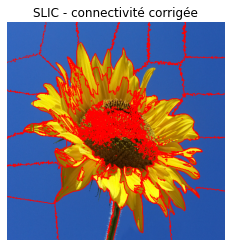

In [12]:
labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels)

contour_img = img_rgb_resized.copy()

img_contours = mark_boundaries(contour_img, labels_connected, color=(1,0,0)) 

plt.imshow(img_contours)
plt.title("SLIC - connectivité corrigée")
plt.axis('off')
plt.show()

Là aussi, le temps de calcul de l'algorithme est long. Certes le résultat s'est un peu amélioré, cependant il n'est toujours pas satisfisant, loin de là même. On s'en rend bien compte en comparant avec la segmentation proposé par la fonction "slic" de scikit, pour la même image.

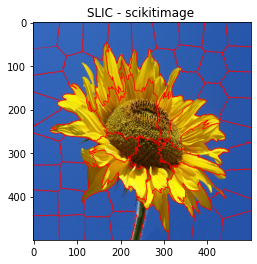

In [13]:
# comparaison avec la fonction SLIC de scikit
img = io.imread(path_images+'fleur.jpg')
img_resized = cv2.resize(img, (500,500))

# SLIC
segments = slic(img_resized, n_segments=80, compactness=10, start_label=0)

img_contour = mark_boundaries(img_resized, segments, color=(1, 0, 0))  
plt.imshow(img_contour)
plt.title("SLIC - scikitimage ")
plt.show()

## Seconde implémentation de SLIC

Dès lors, nous avons deux choses à améliorer absolument: la rapidité d'exécution et la qualité de la segmentation.  
Pour ce qui est de l'amélioration de la rapidité d'exécution, nous nous sommes tournés vers une approche vectorisée de l'algorithme: on ne parcourt plus tous les superpixels de l'image à l'aide de boucles imbriquées infinies, désormais on utilise des masques et on calcule tous les éléments nécessaires en une seule opération.

In [14]:
def compute_distance_vectorized(pixels_lab, coords_i, coords_j, centroid, S, m):

    dc = np.linalg.norm(pixels_lab - centroid[:3], axis=2)  # distance couleur
    ds = np.sqrt((coords_i - centroid[3])**2 + (coords_j - centroid[4])**2)  # distance spatiale
    D = np.sqrt((dc / m)**2 + (ds / S)**2)
    
    return D

Ainsi, on obtient une version vectorisée beaucoup plus performante de notre algorithme.

In [15]:
def slic_manual_vectorized(img_lab, centroids, S, m=10, max_iter=10):
    H, W = img_lab.shape[:2]
    gradient = np.sum(gaussian_gradient_magnitude(img_lab, sigma=1), axis=2)

    centroids[:, 3:5] = np.round(centroids[:, 3:5])

    # Ajustement initial vers min du gradient
    for idx, c in enumerate(centroids):
        x, y = int(c[3]), int(c[4])
        x_min, x_max = max(x - 1, 0), min(x + 2, H)
        y_min, y_max = max(y - 1, 0), min(y + 2, W)
        window = gradient[x_min:x_max, y_min:y_max]
        if window.size > 0:
            min_idx = np.unravel_index(np.argmin(window), window.shape)
            centroids[idx, 3] = x_min + min_idx[0]
            centroids[idx, 4] = y_min + min_idx[1]

    labels = -np.ones((H, W), dtype=np.int32)
    distances = np.full((H, W), np.inf)

    # Pré-calcul des coordonnées globales
    coords_i, coords_j = np.indices((H, W))

    for it in range(max_iter):
        print(f"Iteration {it+1}/{max_iter}")
        distances[:] = np.inf

        # Étape principale vectorisée
        for idx, c in enumerate(centroids):
            cx, cy = int(c[3]), int(c[4])
            x_min, x_max = max(cx - S, 0), min(cx + S, H - 1)
            y_min, y_max = max(cy - S, 0), min(cy + S, W - 1)

            # Slices directs sans meshgrid
            region_lab = img_lab[int(x_min):int(x_max)+1, int(y_min):int(y_max)+1]
            sub_i = coords_i[int(x_min):int(x_max)+1, int(y_min):int(y_max)+1]
            sub_j = coords_j[int(x_min):int(x_max)+1, int(y_min):int(y_max)+1]

            D = compute_distance_vectorized(region_lab, sub_i, sub_j, c, S, m)

            mask = D < distances[int(x_min):int(x_max)+1, int(y_min):int(y_max)+1]
            distances[int(x_min):int(x_max)+1, int(y_min):int(y_max)+1][mask] = D[mask]
            labels[int(x_min):int(x_max)+1, int(y_min):int(y_max)+1][mask] = idx

        # Recalcule des centroïdes (moyenne sur masques)
        new_centroids = np.zeros_like(centroids)
        for k in range(len(centroids)):
            mask = (labels == k)
            if np.any(mask):
                pixels = img_lab[mask]
                coords = np.argwhere(mask)
                new_centroids[k, :3] = pixels.mean(axis=0)
                new_centroids[k, 3:] = coords.mean(axis=0)
            else:
                new_centroids[k] = centroids[k]

        shift = np.linalg.norm(new_centroids - centroids)
        print(f" centroïdes = {shift:.4f}")
        centroids = new_centroids
        if shift < 1e-4:
            print("→ Convergence atteinte.")
            break

    return labels, centroids

Pour tester cette nouvelle version, nous avons choisi une image de petite taille et plutôt simple car il y a peu de détails.

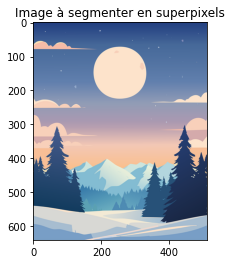

In [16]:
img = cv2.imread(path_images+'foret_neige.png',1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb )
plt.title("Image à segmenter en superpixels")
plt.show()

In [17]:
img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2LAB).astype(np.float64)
labels, centroids = chronometrer(
    slic_manual_vectorized,
    "SLIC manuel",
    img_lab,    
    centroids,  
    S,          
    10,         
    30         
)

Iteration 1/30
 centroïdes = 427.6483
Iteration 2/30
 centroïdes = 126.1516
Iteration 3/30
 centroïdes = 84.8754
Iteration 4/30
 centroïdes = 76.2133
Iteration 5/30
 centroïdes = 47.8218
Iteration 6/30
 centroïdes = 41.6926
Iteration 7/30
 centroïdes = 43.5977
Iteration 8/30
 centroïdes = 47.9251
Iteration 9/30
 centroïdes = 49.7458
Iteration 10/30
 centroïdes = 48.7384
Iteration 11/30
 centroïdes = 33.8284
Iteration 12/30
 centroïdes = 40.5442
Iteration 13/30
 centroïdes = 50.0262
Iteration 14/30
 centroïdes = 55.7643
Iteration 15/30
 centroïdes = 32.3601
Iteration 16/30
 centroïdes = 19.0188
Iteration 17/30
 centroïdes = 31.8051
Iteration 18/30
 centroïdes = 30.0711
Iteration 19/30
 centroïdes = 35.9942
Iteration 20/30
 centroïdes = 31.7827
Iteration 21/30
 centroïdes = 29.6573
Iteration 22/30
 centroïdes = 36.2721
Iteration 23/30
 centroïdes = 44.6168
Iteration 24/30
 centroïdes = 19.7168
Iteration 25/30
 centroïdes = 12.7802
Iteration 26/30
 centroïdes = 11.3169
Iteration 27/30
 ce

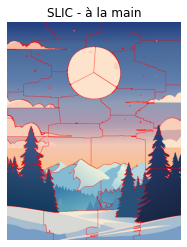

In [18]:
edges = np.zeros_like(labels, dtype=bool)
edges[1: , :] |= (labels[1: , :] != labels[:-1, :])
edges[: , 1:] |= (labels[: , 1:] != labels[: , :-1])

img_contour = img_rgb.copy()
img_contour[edges] = [255, 0, 0]   # contour en rouge
plt.imshow(img_contour)
plt.title("SLIC - à la main")
plt.axis('off')
plt.show()

Dès lors, la différence dans le temps de calcul et le résultat est sans appel par rapport à la version non vectorisée: on obtient une segmentation clean de l'image en quelques secondes seulement. Cette version vectorisée nous permet d'effectuer plus d'itérations (30 ici) ce qui implique qu'on obtient un meilleur résultat final.

Cependant, ce résultat peut être améliorer grâce au post-traitement. En effet, on constate un certain nombre de pixels isolés, ce qu'on ne souhaite évidemment pas.

Temps d'exécution de enforce_connectivity_fast : 1.05 sec


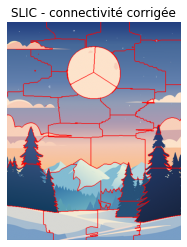

In [19]:
labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels)

contour_img2 = img_rgb.copy()

img_contours = mark_boundaries(contour_img2, labels_connected, color=(1,0,0)) 

plt.imshow(img_contours)
plt.title("SLIC - connectivité corrigée")
plt.axis('off')
plt.show()

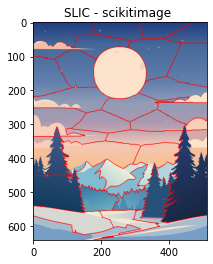

In [20]:
# comparaison avec la fonction SLIC de scikit
img = io.imread(path_images+'foret_neige.png')

# SLIC
segments = slic(img, n_segments=40, compactness=10, start_label=0)

# Afficher les superpixels
img_contour = mark_boundaries(img, segments, color=(1, 0, 0))  
plt.imshow(img_contour)
plt.title("SLIC - scikitimage ")
plt.show()

Enfin, pour cette image simple, le résultat est plutôt très satisfaisant. Notamment quand on le compare à SLIC de scikit. Cette seconde approche permet de mettre en évidence l'importante du choix des paramètres. En effet, pour l'image "foret_neige", K=80 marche vraiment bien alors que pour l'image qui suit "candle_light", il faut un K très grand pour avoir une découpe en superpixel un minimum potable. Ainsi, on comprend bien qu'il faudrait pouvoir adapter K à chaque image, c'est ce qu'on va développer par la suite.

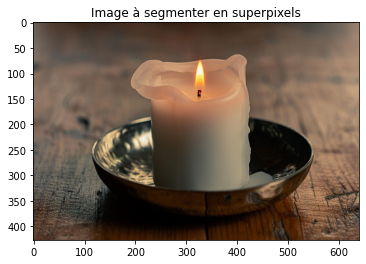

Iteration 1/30
 centroïdes = 565.5135
Iteration 2/30
 centroïdes = 149.2513
Iteration 3/30
 centroïdes = 69.0478
Iteration 4/30
 centroïdes = 50.4128
Iteration 5/30
 centroïdes = 44.7383
Iteration 6/30
 centroïdes = 33.4803
Iteration 7/30
 centroïdes = 25.8761
Iteration 8/30
 centroïdes = 23.5906
Iteration 9/30
 centroïdes = 21.7938
Iteration 10/30
 centroïdes = 21.5007
Iteration 11/30
 centroïdes = 21.2434
Iteration 12/30
 centroïdes = 19.6244
Iteration 13/30
 centroïdes = 16.2249
Iteration 14/30
 centroïdes = 14.3651
Iteration 15/30
 centroïdes = 14.1313
Iteration 16/30
 centroïdes = 14.1178
Iteration 17/30
 centroïdes = 13.7133
Iteration 18/30
 centroïdes = 14.4776
Iteration 19/30
 centroïdes = 14.0675
Iteration 20/30
 centroïdes = 14.5647
Iteration 21/30
 centroïdes = 16.8446
Iteration 22/30
 centroïdes = 20.6560
Iteration 23/30
 centroïdes = 19.2568
Iteration 24/30
 centroïdes = 9.0109
Iteration 25/30
 centroïdes = 8.2044
Iteration 26/30
 centroïdes = 7.3234
Iteration 27/30
 centr

In [21]:
img = cv2.imread(path_images+'candle_light.jpg',1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Image à segmenter en superpixels")
plt.show()
img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2LAB).astype(np.float64)
labels, centroids = chronometrer(
    slic_manual_vectorized,
    "SLIC manuel",
    img_lab,    
    centroids,  
    S,          
    10,         
    30         
)

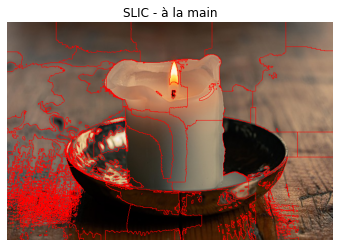

In [22]:
edges = np.zeros_like(labels, dtype=bool)
edges[1: , :] |= (labels[1: , :] != labels[:-1, :])
edges[: , 1:] |= (labels[: , 1:] != labels[: , :-1])

img_contour = img_rgb.copy()
img_contour[edges] = [255, 0, 0] 
plt.imshow(img_contour)
plt.title("SLIC - à la main")
plt.axis('off')
plt.show()

Pour cette image, la segmentation en superpixels est mauvaise, notamment à cause de sa complexité (beaucoup de détails dans la partie inférieure de l'image). On comprend qu'il va être important de choisir au mieux le couple de paramètres (K,m) et qu'il sera nécessaire de développer l'étape de post-traitement.

## Troisième implémentation: choix du nombre de superpixels (K) et de *m* (compacité)

En ce qui concerne les paramètres de SLIC:  

Plus **K est petit**, plus chaque superpixel couvre une grande zone: détails perdus, contours mal suivis.  
Quand **K augmente**, les superpixels deviennent plus petits.

Aussi, **m** règle l'équilibre entre fidélité envers les contours et régularité des formes:

- **m faible**: SLIC suit mieux les contours fins, au risque de segments plus irréguliers.
- **m élevé**: superpixels plus compacts et réguliers, mais moins collés aux bords.

On va donc chercher à améliorer nos résultats en jouant sur ces paramètres. Pour cela, il nous faut une fonction SLIC qui les prend en paramètres. 

On teste plusieurs couples **(K, m)** pour mesurer :
- **time_s**: temps d’exécution,
- **n_segments_real**: nb réel de superpixels (doit être **proche de K**),

Choisir une meilleure config dépend de l’objectif :
- **Rapidité**: min(time_s)
- **Respect de K**: min(|n_segments_real − K|)
- **Compromis**: pondération des deux paramètres

En résumé, on va chercher quels paramètres K et m donne la meilleure segmentation pour notre image et on va garder les meilleures valeurs de paramètres.

In [23]:
def _init_centroids_grid(img_lab, K):
    H, W = img_lab.shape[:2]
    N = H * W
    S = np.sqrt(N / K) # espacement moyen entre deux centroïdes
    step = max(1, int(round(S)))
    
    # coordonnées espacées régulièrement
    xs = np.arange(step // 2, H, step)
    ys = np.arange(step // 2, W, step)

    centers = [(int(x), int(y)) for x in xs for y in ys]
    rng = np.random.default_rng(42)
    
    # ajustement pour obtenir exactement K centroïdes
    if len(centers) < K:
        # complété en ajoutant des points pseudo-aléatoires espacées (rng)
        centers += [(int(rng.integers(0, H)), int(rng.integers(0, W))) for _ in range(K - len(centers))]
    elif len(centers) > K:
        centers = centers[:K]

    # création du tableau des centroïdes avec leurs coordonnées et valeurs Lab
    centroids = np.zeros((K, 5))
    for i, (x, y) in enumerate(centers):
        centroids[i, :3] = img_lab[x, y]
        centroids[i, 3:] = [x, y]
    return centroids, S

def slic_manuelle(img_input, K, m, max_iter=10,
                  enforce_connectivity=True,
                  connectivity_min_size_ratio=0.25,
                  assume_rgb=True):
    
    # conversion couleur -> Lab
    if assume_rgb:
        # on normalise en [0,1] si nécessaire
        img_rgb = img_input.astype(np.float64)
        if img_rgb.max() > 1.5: # suppose 0..255
            img_rgb /= 255.0
        img_lab = rgb2lab(img_rgb)
    else:
        # si l'image est BGR, conversion via OpenCV
        img_lab = cv2.cvtColor(img_input, cv2.COLOR_BGR2LAB).astype(np.float64)
    
    # initialisation des centroïdes
    centroids, S = _init_centroids_grid(img_lab, K)
    
    # appel à l'algorithme SLIC
    labels, centroids = slic_manual_vectorized(img_lab, centroids, S, m, max_iter)
    
    # appel à la connectivité pour le post-traitement
    if enforce_connectivity:
        labels = enforce_connectivity_fast(labels, connectivity_min_size_ratio)

    return labels, centroids, S

def grid_search_slic_manuelle(
    img_rgb: np.ndarray,
    K_list,
    m_list,
    max_iter: int = 10,
    assume_rgb: bool = True,
    enforce_connectivity: bool = True,
    connectivity_min_size_ratio: float = 0.25,
) :
    
    import time
    results = []
    for K in K_list:
        for m in m_list:
            t0 = time.time()
            labels, centroids, S = slic_manuelle(
                img_rgb, K, m,
                max_iter=max_iter,
                enforce_connectivity=enforce_connectivity,
                connectivity_min_size_ratio=connectivity_min_size_ratio,
                assume_rgb=assume_rgb,
            )
            dt = time.time() - t0 # durée d'exécution
            n_segments_real = len(np.unique(labels))  # nombre réel de superpixels obtenus
            
            # enregistrement des résultats
            results.append({
                "K": K,
                "m": m,
                "time_s": dt,
                "S": S,
                "n_segments_real": n_segments_real,
            })
    return {"runs": results}

Testons à nouveau l'image précédente avec une valeur plus haute pour K.

Iteration 1/10
 centroïdes = 92.6412
Iteration 2/10
 centroïdes = 32.8756
Iteration 3/10
 centroïdes = 20.5814
Iteration 4/10
 centroïdes = 15.4485
Iteration 5/10
 centroïdes = 13.0528
Iteration 6/10
 centroïdes = 11.7654
Iteration 7/10
 centroïdes = 10.9115
Iteration 8/10
 centroïdes = 9.8255
Iteration 9/10
 centroïdes = 8.6912
Iteration 10/10
 centroïdes = 7.7271
Temps d'exécution de SLIC manuel complète : 6.67 sec


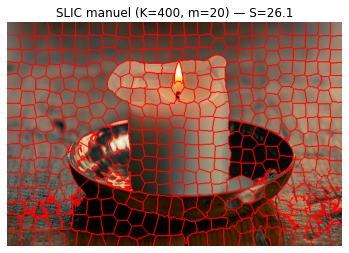

In [24]:
K = 400
m = 20
max_iter = 10

labels, centroids, S = chronometrer(
    slic_manuelle,
    "SLIC manuel complète",
    img,     # image source
    K,           # nombre de superpixels
    m,           # compacité
    max_iter,    # nombre d'itérations
    True,        # enforce_connectivity
    0.25,        # ratio de taille minimale
    True         # assume_rgb
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"SLIC manuel (K={K}, m={m}) — S={S:.1f}")
plt.axis("off")
plt.show()

On a un résultat plutot intéressant: la segmentation est meilleur mais ce problème a été réglé uniquement pas la mise en place d'un K très grand. Or on aimerait pouvoir découper l'image, quelquequ'elle soit, en peu de superpixels , ici c'est trop segmenté. De plus, on a fixé K et m purement arbitrairement. Maintenant, testons le gridSearch pour cette image. On se donne certes une liste également arbitraires de valeurs de K et m. Cependant on pourrait imaginer ré-effectuer une recherche du meilleur couple (K,m) suite à la première.  
Par exemple, si on détermine parmis les K_list = [60, 120, 240], m_list = [5, 10, 20] que le couple optimal est (60,20), on pourrait imaginer améliorer encore la finesse des paramètres en proposant une nouvelle recherche du couple optimal mais sur une K_list plus proche du paramètre optimal, par exemple on ré-itère avec K_list = [40, 60, 80], m_list = [5, 10, 20]. Pour cette recherche, on peut désactiver le post-traitement par enforce_connectivity selon nos priorités: réduction de la précision du paramètre mais diminution du temps de calcul et inversement. On estime ici qu'il est préférable de retirer ce post-traitement dans la recherche de paramètre car le gain en précision est infime par rapport au temps de calcul nécessaire à sa mise en place. De plus, on peut comme "contourner" cette étape si on ré-itère sur une K_list plus précise.

In [25]:
K_list = [60, 120, 240]
m_list = [5, 10, 20]

resultats = grid_search_slic_manuelle(
    img_rgb = img_rgb,
    K_list = K_list,
    m_list = m_list,
    max_iter = 4,
    assume_rgb = True,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25
)

print("Résultats du grid-search :")
for run in resultats["runs"]:
    print(f"K={run['K']:<4} | m={run['m']:<3} | temps={run['time_s']:.2f}s | "
          f"segments réels={run['n_segments_real']} | S={run['S']:.1f}")

Iteration 1/4
 centroïdes = 131.1477
Iteration 2/4
 centroïdes = 71.7969
Iteration 3/4
 centroïdes = 41.6787
Iteration 4/4
 centroïdes = 34.8687
Iteration 1/4
 centroïdes = 108.7394
Iteration 2/4
 centroïdes = 59.8140
Iteration 3/4
 centroïdes = 38.0356
Iteration 4/4
 centroïdes = 29.0217
Iteration 1/4
 centroïdes = 91.6009
Iteration 2/4
 centroïdes = 43.5361
Iteration 3/4
 centroïdes = 27.0138
Iteration 4/4
 centroïdes = 20.4973
Iteration 1/4
 centroïdes = 123.7330
Iteration 2/4
 centroïdes = 58.0259
Iteration 3/4
 centroïdes = 38.3132
Iteration 4/4
 centroïdes = 30.6252
Iteration 1/4
 centroïdes = 107.1284
Iteration 2/4
 centroïdes = 48.9394
Iteration 3/4
 centroïdes = 31.8945
Iteration 4/4
 centroïdes = 25.9024
Iteration 1/4
 centroïdes = 86.1456
Iteration 2/4
 centroïdes = 32.9690
Iteration 3/4
 centroïdes = 23.8985
Iteration 4/4
 centroïdes = 19.2776
Iteration 1/4
 centroïdes = 120.4584
Iteration 2/4
 centroïdes = 53.7569
Iteration 3/4
 centroïdes = 37.6205
Iteration 4/4
 centroïd

In [26]:
best_balanced = min(
    resultats["runs"],
    key=lambda r: (r["time_s"] * 0.3 + abs(r["n_segments_real"] - r["K"]) * 0.7)
)
print("Meilleur compromis :", best_balanced)

Meilleur compromis : {'K': 60, 'm': 20, 'time_s': 0.4800698757171631, 'S': 67.4882705858334, 'n_segments_real': 60}


Iteration 1/10
 centroïdes = 91.6009
Iteration 2/10
 centroïdes = 43.5361
Iteration 3/10
 centroïdes = 27.0138
Iteration 4/10
 centroïdes = 20.4973
Iteration 5/10
 centroïdes = 16.4024
Iteration 6/10
 centroïdes = 15.2087
Iteration 7/10
 centroïdes = 13.1913
Iteration 8/10
 centroïdes = 11.8282
Iteration 9/10
 centroïdes = 9.8331
Iteration 10/10
 centroïdes = 8.2674


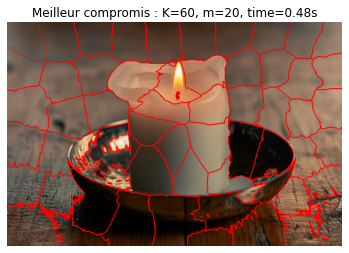

In [27]:
labels, centroids, S = slic_manuelle(
    img_input = img_rgb,
    K = best_balanced['K'],
    m = best_balanced['m'],
    max_iter = 10,
    enforce_connectivity = True,
    connectivity_min_size_ratio = 0.25,
    assume_rgb = True
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"Meilleur compromis : K={best_balanced['K']}, m={best_balanced['m']}, time={best_balanced['time_s']:.2f}s")
plt.axis("off")
plt.show()

Le résultat est satisfaisant mais il reste des imperfections. Pour corriger cela, on va appliquer la correction post-traitement plusieurs fois. C'est très rapide une fois le premier post-traitement effectué car les corrections sont de plus en plus infimes.

Temps d'exécution de enforce_connectivity_fast : 0.31 sec
Temps d'exécution de enforce_connectivity_fast : 0.15 sec
Temps d'exécution de enforce_connectivity_fast : 0.14 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécution de enforce_connectivity_fast : 0.13 sec
Temps d'exécut

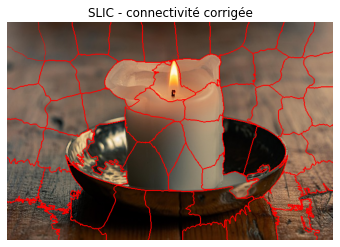

In [28]:
labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels)

# plusieurs post-traitement
for _ in range(30):
    labels_connected = chronometrer(enforce_connectivity_fast, 
                                    "enforce_connectivity_fast", 
                                    labels_connected)

img_contours = mark_boundaries(img_rgb, labels_connected, color=(1,0,0)) 

plt.imshow(img_contours)
plt.title("SLIC - connectivité corrigée")
plt.axis('off')
plt.show()

On compare avec la version de scikit.

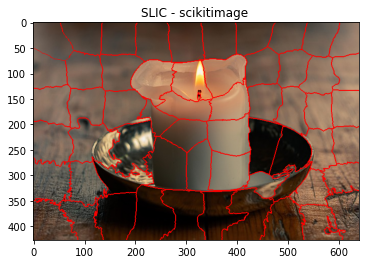

In [29]:
segments = slic(img, n_segments=best_balanced['n_segments_real'], compactness=best_balanced['m'], start_label=0)

img_contour = mark_boundaries(img_rgb, segments, color=(1, 0, 0))  
plt.imshow(img_contour)
plt.title("SLIC - scikitimage ")
plt.show()

On obtient un résultat sensiblement proche de celui fourni par la méthode "slic" de scikit. La segmentation est casiment similaire sur beaucoup de parties de l'image.

## Application de l'algorithme SLIC à quelques images 

### Image 1

Appliquons d'abord notre SLIC à une image très colorée, avec une faible résolution et peu de détail.

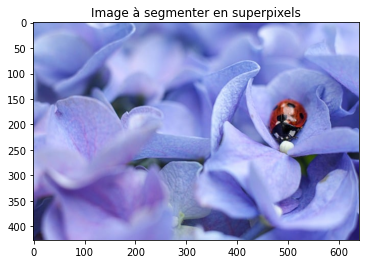

In [30]:
img = cv2.imread(path_images+'violet.jpg',1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Image à segmenter en superpixels")
plt.show()

img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2LAB).astype(np.float64)

Après avoir visualisé l'image, on effectue une première exécution de SLIC, avec (K,m) complètement arbitraire, pour deux raisons:
- d'abord, voir si il y a necessité à rechercher des paramètres optimal car si la segmentation est satisfaisante on pourrait presque la garder
- puis, pour se rendre compte de l'allure de la segmentation, pour voir notamment les aspects de la photo qui pourrait poser problème.

Iteration 1/10
 centroïdes = 137.3603
Iteration 2/10
 centroïdes = 58.5760
Iteration 3/10
 centroïdes = 49.1509
Iteration 4/10
 centroïdes = 37.5758
Iteration 5/10
 centroïdes = 24.3007
Iteration 6/10
 centroïdes = 20.2645
Iteration 7/10
 centroïdes = 19.4182
Iteration 8/10
 centroïdes = 29.1703
Iteration 9/10
 centroïdes = 20.5650
Iteration 10/10
 centroïdes = 14.9667
Temps d'exécution de SLIC manuel complète : 1.73 sec


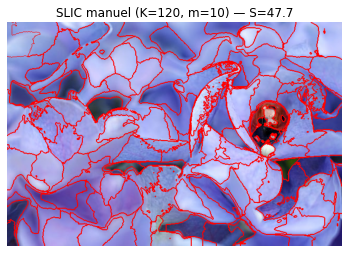

In [31]:
K = 120
m = 10
max_iter = 10

labels, centroids, S = chronometrer(
    slic_manuelle,
    "SLIC manuel complète",
    img,     # image source
    K,           # nombre de superpixels
    m,           # compacité
    max_iter,    # nombre d'itérations
    False,        # enforce_connectivity
    0.25,        # ratio de taille minimale
    True         # assume_rgb
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"SLIC manuel (K={K}, m={m}) — S={S:.1f}")
plt.axis("off")
plt.show()

Maintenant, cherchons (K,m) optimal.

In [32]:
K_list = [50, 100, 130]
m_list = [8, 14, 20]

resultats = grid_search_slic_manuelle(
    img_rgb = img_rgb,
    K_list = K_list,
    m_list = m_list,
    max_iter = 4,
    assume_rgb = True,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25
)

print("Résultats du grid-search :")
for run in resultats["runs"]:
    print(f"K={run['K']:<4} | m={run['m']:<3} | temps={run['time_s']:.2f}s | "
          f"segments réels={run['n_segments_real']} | S={run['S']:.1f}")

Iteration 1/4
 centroïdes = 141.0828
Iteration 2/4
 centroïdes = 84.0302
Iteration 3/4
 centroïdes = 54.5597
Iteration 4/4
 centroïdes = 55.7864
Iteration 1/4
 centroïdes = 130.3529
Iteration 2/4
 centroïdes = 74.2794
Iteration 3/4
 centroïdes = 44.1572
Iteration 4/4
 centroïdes = 33.0393
Iteration 1/4
 centroïdes = 122.8317
Iteration 2/4
 centroïdes = 66.3923
Iteration 3/4
 centroïdes = 33.8357
Iteration 4/4
 centroïdes = 28.0677
Iteration 1/4
 centroïdes = 142.0626
Iteration 2/4
 centroïdes = 71.1862
Iteration 3/4
 centroïdes = 49.9880
Iteration 4/4
 centroïdes = 39.8816
Iteration 1/4
 centroïdes = 127.3545
Iteration 2/4
 centroïdes = 59.1985
Iteration 3/4
 centroïdes = 47.4508
Iteration 4/4
 centroïdes = 38.0851
Iteration 1/4
 centroïdes = 118.7667
Iteration 2/4
 centroïdes = 52.5158
Iteration 3/4
 centroïdes = 38.9186
Iteration 4/4
 centroïdes = 30.7974
Iteration 1/4
 centroïdes = 150.7109
Iteration 2/4
 centroïdes = 67.9469
Iteration 3/4
 centroïdes = 44.7981
Iteration 4/4
 centro

La fonction de coût nous renvoie le meilleur compromis temps de calcul / segmentation.

In [33]:
best_balanced = min(
    resultats["runs"],
    key=lambda r: (r["time_s"] * 0.1 + abs(r["n_segments_real"] - r["K"]) * 0.9)
)
print("Meilleur compromis :", best_balanced)

Meilleur compromis : {'K': 50, 'm': 20, 'time_s': 0.44483256340026855, 'S': 73.9296963337467, 'n_segments_real': 50}


Iteration 1/10
 centroïdes = 122.8317
Iteration 2/10
 centroïdes = 66.3923
Iteration 3/10
 centroïdes = 33.8357
Iteration 4/10
 centroïdes = 28.0677
Iteration 5/10
 centroïdes = 23.8447
Iteration 6/10
 centroïdes = 22.4657
Iteration 7/10
 centroïdes = 18.9001
Iteration 8/10
 centroïdes = 14.5319
Iteration 9/10
 centroïdes = 10.8940
Iteration 10/10
 centroïdes = 8.0155


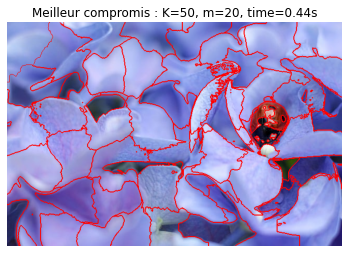

In [34]:
labels, centroids, S = slic_manuelle(
    img_input = img_rgb,
    K = best_balanced['K'],
    m = best_balanced['m'],
    max_iter = 10,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25,
    assume_rgb = True
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"Meilleur compromis : K={best_balanced['K']}, m={best_balanced['m']}, time={best_balanced['time_s']:.2f}s")
plt.axis("off")
plt.show()

C'est mieux mais une étape de post-traitement est nécessaire.

Temps d'exécution de enforce_connectivity_fast : 0.47 sec
Temps d'exécution de enforce_connectivity_fast : 0.19 sec
Temps d'exécution de enforce_connectivity_fast : 0.12 sec
Temps d'exécution de enforce_connectivity_fast : 0.11 sec
Temps d'exécution de enforce_connectivity_fast : 0.11 sec
Temps d'exécution de enforce_connectivity_fast : 0.12 sec
Temps d'exécution de enforce_connectivity_fast : 0.12 sec
Temps d'exécution de enforce_connectivity_fast : 0.11 sec
Temps d'exécution de enforce_connectivity_fast : 0.11 sec
Temps d'exécution de enforce_connectivity_fast : 0.11 sec
Temps d'exécution de enforce_connectivity_fast : 0.11 sec
Temps d'exécution de enforce_connectivity_fast : 0.11 sec
Temps d'exécution de enforce_connectivity_fast : 0.12 sec
Temps d'exécution de enforce_connectivity_fast : 0.12 sec
Temps d'exécution de enforce_connectivity_fast : 0.12 sec
Temps d'exécution de enforce_connectivity_fast : 0.12 sec
Temps d'exécution de enforce_connectivity_fast : 0.11 sec
Temps d'exécut

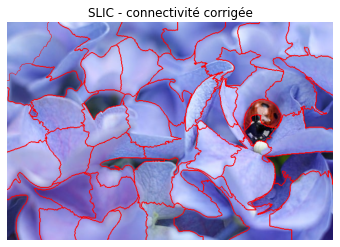

In [35]:
labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels)
for _ in range(30):
    labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels_connected)

img_contours = mark_boundaries(img_rgb, labels_connected, color=(1,0,0)) 

plt.imshow(img_contours)
plt.title("SLIC - connectivité corrigée")
plt.axis('off')
plt.show()

Finalement, on obtient une segmentation très satisfaisante de notre image, dans un temps très court. Donc pour ce genre d'images, l'algorithme est rapide et efficace.

### Image 2

Passons désormais à une image en partie très colorée (sauf au centre), de plus grande résolution et avec un niveau de détail très élevé.

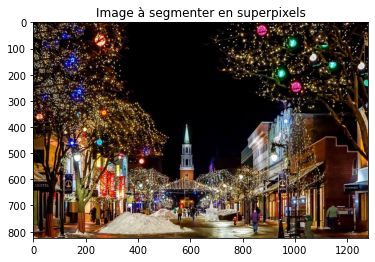

In [36]:
img = cv2.imread(path_images+'noel.jpg',1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Image à segmenter en superpixels")
plt.show()

img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2LAB).astype(np.float64)

Iteration 1/10
 centroïdes = 264.2343
Iteration 2/10
 centroïdes = 143.3633
Iteration 3/10
 centroïdes = 109.9948
Iteration 4/10
 centroïdes = 96.1537
Iteration 5/10
 centroïdes = 77.9003
Iteration 6/10
 centroïdes = 66.2109
Iteration 7/10
 centroïdes = 58.6876
Iteration 8/10
 centroïdes = 46.7358
Iteration 9/10
 centroïdes = 42.5363
Iteration 10/10
 centroïdes = 41.1139
Temps d'exécution de SLIC manuel complète : 6.64 sec


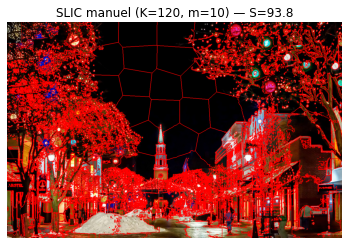

In [37]:
K = 120
m = 10
max_iter = 10

labels, centroids, S = chronometrer(
    slic_manuelle,
    "SLIC manuel complète",
    img,     # image source
    K,           # nombre de superpixels
    m,           # compacité
    max_iter,    # nombre d'itérations
    False,        # enforce_connectivity
    0.25,        # ratio de taille minimale
    True         # assume_rgb
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"SLIC manuel (K={K}, m={m}) — S={S:.1f}")
plt.axis("off")
plt.show()

In [38]:
K_list = [50, 100, 130]
m_list = [8, 14, 20]

resultats = grid_search_slic_manuelle(
    img_rgb = img_rgb,
    K_list = K_list,
    m_list = m_list,
    max_iter = 4,
    assume_rgb = True,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25
)

print("Résultats du grid-search :")
for run in resultats["runs"]:
    print(f"K={run['K']:<4} | m={run['m']:<3} | temps={run['time_s']:.2f}s | "
          f"segments réels={run['n_segments_real']} | S={run['S']:.1f}")

Iteration 1/4
 centroïdes = 261.2509
Iteration 2/4
 centroïdes = 122.7301
Iteration 3/4
 centroïdes = 90.4241
Iteration 4/4
 centroïdes = 82.0392
Iteration 1/4
 centroïdes = 251.1012
Iteration 2/4
 centroïdes = 113.1290
Iteration 3/4
 centroïdes = 71.2302
Iteration 4/4
 centroïdes = 59.3023
Iteration 1/4
 centroïdes = 241.7237
Iteration 2/4
 centroïdes = 101.8989
Iteration 3/4
 centroïdes = 62.2805
Iteration 4/4
 centroïdes = 48.7408
Iteration 1/4
 centroïdes = 237.1807
Iteration 2/4
 centroïdes = 145.2467
Iteration 3/4
 centroïdes = 104.6174
Iteration 4/4
 centroïdes = 103.1131
Iteration 1/4
 centroïdes = 230.0027
Iteration 2/4
 centroïdes = 129.8207
Iteration 3/4
 centroïdes = 98.1663
Iteration 4/4
 centroïdes = 82.2949
Iteration 1/4
 centroïdes = 224.1128
Iteration 2/4
 centroïdes = 117.6288
Iteration 3/4
 centroïdes = 87.0094
Iteration 4/4
 centroïdes = 68.1564
Iteration 1/4
 centroïdes = 252.2994
Iteration 2/4
 centroïdes = 140.5729
Iteration 3/4
 centroïdes = 110.0906
Iteration 4

In [39]:
best_balanced = min(
    resultats["runs"],
    key=lambda r: (r["time_s"] * 0.1 + abs(r["n_segments_real"] - r["K"]) * 0.9)
)
print("Meilleur compromis :", best_balanced)

Meilleur compromis : {'K': 50, 'm': 20, 'time_s': 1.7353522777557373, 'S': 145.2391131892508, 'n_segments_real': 50}


Iteration 1/10
 centroïdes = 241.7237
Iteration 2/10
 centroïdes = 101.8989
Iteration 3/10
 centroïdes = 62.2805
Iteration 4/10
 centroïdes = 48.7408
Iteration 5/10
 centroïdes = 45.8574
Iteration 6/10
 centroïdes = 37.8544
Iteration 7/10
 centroïdes = 39.6189
Iteration 8/10
 centroïdes = 43.5190
Iteration 9/10
 centroïdes = 51.8551
Iteration 10/10
 centroïdes = 39.9592


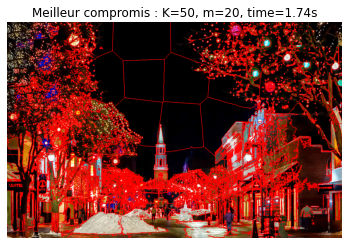

In [40]:
labels, centroids, S = slic_manuelle(
    img_input = img_rgb,
    K = best_balanced['K'],
    m = best_balanced['m'],
    max_iter = 10,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25,
    assume_rgb = True
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"Meilleur compromis : K={best_balanced['K']}, m={best_balanced['m']}, time={best_balanced['time_s']:.2f}s")
plt.axis("off")
plt.show()

Temps d'exécution de enforce_connectivity_fast : 103.58 sec
Temps d'exécution de enforce_connectivity_fast : 30.38 sec
Temps d'exécution de enforce_connectivity_fast : 8.47 sec
Temps d'exécution de enforce_connectivity_fast : 2.24 sec
Temps d'exécution de enforce_connectivity_fast : 1.43 sec
Temps d'exécution de enforce_connectivity_fast : 1.23 sec
Temps d'exécution de enforce_connectivity_fast : 1.23 sec
Temps d'exécution de enforce_connectivity_fast : 1.22 sec
Temps d'exécution de enforce_connectivity_fast : 1.23 sec
Temps d'exécution de enforce_connectivity_fast : 1.23 sec
Temps d'exécution de enforce_connectivity_fast : 1.23 sec
Temps d'exécution de enforce_connectivity_fast : 1.25 sec
Temps d'exécution de enforce_connectivity_fast : 1.23 sec
Temps d'exécution de enforce_connectivity_fast : 1.23 sec
Temps d'exécution de enforce_connectivity_fast : 1.24 sec
Temps d'exécution de enforce_connectivity_fast : 1.24 sec
Temps d'exécution de enforce_connectivity_fast : 1.23 sec
Temps d'exé

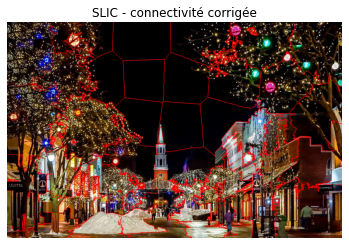

In [41]:
labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels)
for _ in range(30):
    labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels_connected)

    
img_contours = mark_boundaries(img_rgb, labels_connected, color=(1,0,0)) 

plt.imshow(img_contours)
plt.title("SLIC - connectivité corrigée")
plt.axis('off')
plt.show()

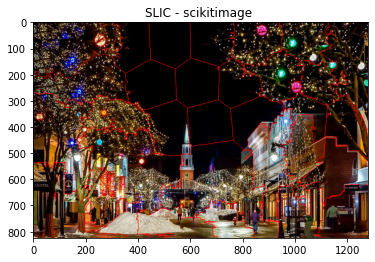

In [42]:
# segmentation slic selon scikit 
segments = slic(img_rgb, n_segments=50, compactness=20, start_label=0)

img_contour = mark_boundaries(img_rgb, segments, color=(1, 0, 0))  
plt.imshow(img_contour)
plt.title("SLIC - scikitimage ")
plt.show()

Le SLIC semble plutôt satisfaisant ici, mais c'est encore plus parlant quand on compare avec la fonction "slic" de scikit. En effet, on constate que la segmentation est vraiment très proche. Donc pour une image avec énormément de détails, l'algorithme se débrouille bien. L'image 2 est de plus grande taille que l'image 1 donc les temps de calcul sont un peu plus long.

### Image 3

Enfin, interessons-nous à une image tout de même assez détaillé, contenant quelques aspects redondants et de grande résolution.

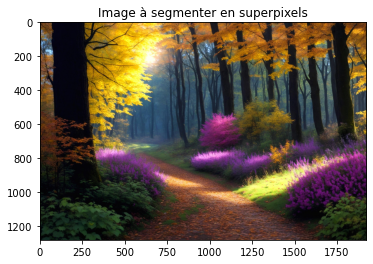

In [43]:
img = cv2.imread(path_images+'fall.jpg',1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Image à segmenter en superpixels")
plt.show()

img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2LAB).astype(np.float64)

Iteration 1/10
 centroïdes = 380.9697
Iteration 2/10
 centroïdes = 212.4937
Iteration 3/10
 centroïdes = 146.2921
Iteration 4/10
 centroïdes = 107.0244
Iteration 5/10
 centroïdes = 88.7923
Iteration 6/10
 centroïdes = 71.9695
Iteration 7/10
 centroïdes = 65.0113
Iteration 8/10
 centroïdes = 66.1549
Iteration 9/10
 centroïdes = 66.8768
Iteration 10/10
 centroïdes = 59.5688
Temps d'exécution de SLIC manuel complète : 15.57 sec


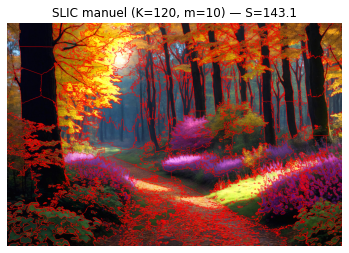

In [44]:
K = 120
m = 10
max_iter = 10

labels, centroids, S = chronometrer(
    slic_manuelle,
    "SLIC manuel complète",
    img,     # image source
    K,           # nombre de superpixels
    m,           # compacité
    max_iter,    # nombre d'itérations
    False,        # enforce_connectivity
    0.25,        # ratio de taille minimale
    True         # assume_rgb
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"SLIC manuel (K={K}, m={m}) — S={S:.1f}")
plt.axis("off")
plt.show()

In [45]:
K_list = [30, 50, 70]
m_list = [8, 14, 20]

resultats = grid_search_slic_manuelle(
    img_rgb = img_rgb,
    K_list = K_list,
    m_list = m_list,
    max_iter = 4,
    assume_rgb = True,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25
)

print("Résultats du grid-search :")
for run in resultats["runs"]:
    print(f"K={run['K']:<4} | m={run['m']:<3} | temps={run['time_s']:.2f}s | "
          f"segments réels={run['n_segments_real']} | S={run['S']:.1f}")

Iteration 1/4
 centroïdes = 452.5682
Iteration 2/4
 centroïdes = 243.7032
Iteration 3/4
 centroïdes = 122.0536
Iteration 4/4
 centroïdes = 98.3462
Iteration 1/4
 centroïdes = 435.8418
Iteration 2/4
 centroïdes = 215.7667
Iteration 3/4
 centroïdes = 137.8982
Iteration 4/4
 centroïdes = 91.6649
Iteration 1/4
 centroïdes = 423.5570
Iteration 2/4
 centroïdes = 196.5841
Iteration 3/4
 centroïdes = 117.0284
Iteration 4/4
 centroïdes = 82.9263
Iteration 1/4
 centroïdes = 417.5350
Iteration 2/4
 centroïdes = 229.5709
Iteration 3/4
 centroïdes = 160.0375
Iteration 4/4
 centroïdes = 93.7134
Iteration 1/4
 centroïdes = 386.0865
Iteration 2/4
 centroïdes = 209.0763
Iteration 3/4
 centroïdes = 147.2493
Iteration 4/4
 centroïdes = 80.4094
Iteration 1/4
 centroïdes = 364.7067
Iteration 2/4
 centroïdes = 187.1076
Iteration 3/4
 centroïdes = 139.5451
Iteration 4/4
 centroïdes = 82.4178
Iteration 1/4
 centroïdes = 405.4477
Iteration 2/4
 centroïdes = 229.0598
Iteration 3/4
 centroïdes = 168.8704
Iterati

In [46]:
best_balanced = min(
    resultats["runs"],
    key=lambda r: (r["time_s"] * 0.1 + abs(r["n_segments_real"] - r["K"]) * 0.9)
)
print("Meilleur compromis :", best_balanced)

Meilleur compromis : {'K': 30, 'm': 20, 'time_s': 3.366936683654785, 'S': 286.2167011199731, 'n_segments_real': 30}


Iteration 1/10
 centroïdes = 423.5570
Iteration 2/10
 centroïdes = 196.5841
Iteration 3/10
 centroïdes = 117.0284
Iteration 4/10
 centroïdes = 82.9263
Iteration 5/10
 centroïdes = 71.8982
Iteration 6/10
 centroïdes = 57.7202
Iteration 7/10
 centroïdes = 50.9094
Iteration 8/10
 centroïdes = 39.7237
Iteration 9/10
 centroïdes = 34.6177
Iteration 10/10
 centroïdes = 33.0689


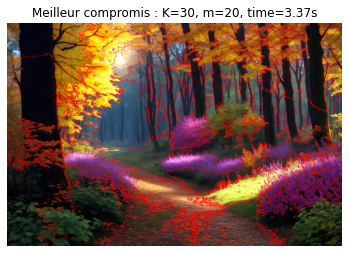

In [47]:
labels, centroids, S = slic_manuelle(
    img_input = img_rgb,
    K = best_balanced['K'],
    m = best_balanced['m'],
    max_iter = 10,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25,
    assume_rgb = True
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"Meilleur compromis : K={best_balanced['K']}, m={best_balanced['m']}, time={best_balanced['time_s']:.2f}s")
plt.axis("off")
plt.show()

In [48]:
labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels)

Temps d'exécution de enforce_connectivity_fast : 64.09 sec


Temps d'exécution de enforce_connectivity_fast : 16.29 sec
Temps d'exécution de enforce_connectivity_fast : 4.01 sec
Temps d'exécution de enforce_connectivity_fast : 2.07 sec
Temps d'exécution de enforce_connectivity_fast : 1.82 sec
Temps d'exécution de enforce_connectivity_fast : 1.57 sec
Temps d'exécution de enforce_connectivity_fast : 1.43 sec
Temps d'exécution de enforce_connectivity_fast : 1.43 sec
Temps d'exécution de enforce_connectivity_fast : 1.43 sec
Temps d'exécution de enforce_connectivity_fast : 1.42 sec
Temps d'exécution de enforce_connectivity_fast : 1.42 sec
Temps d'exécution de enforce_connectivity_fast : 1.42 sec
Temps d'exécution de enforce_connectivity_fast : 1.42 sec
Temps d'exécution de enforce_connectivity_fast : 1.42 sec
Temps d'exécution de enforce_connectivity_fast : 1.53 sec
Temps d'exécution de enforce_connectivity_fast : 1.43 sec
Temps d'exécution de enforce_connectivity_fast : 1.43 sec
Temps d'exécution de enforce_connectivity_fast : 1.42 sec
Temps d'exécu

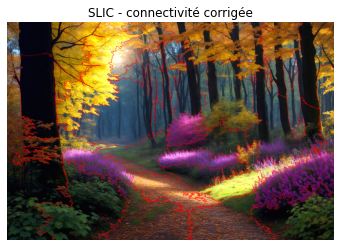

In [49]:
for _ in range(30):
    labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels_connected)

img_contours = mark_boundaries(img_rgb, labels_connected, color=(1,0,0)) 

plt.imshow(img_contours)
plt.title("SLIC - connectivité corrigée")
plt.axis('off')
plt.show()

On obtient un résultat très satisfaisant.

### Retour sur l'image initiale

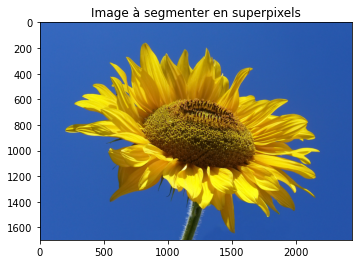

In [50]:
img = cv2.imread(path_images+'fleur.jpg',1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Image à segmenter en superpixels")
plt.show()
img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2LAB).astype(np.float64)

Iteration 1/10
 centroïdes = 348.9732
Iteration 2/10
 centroïdes = 205.8435
Iteration 3/10
 centroïdes = 131.2887
Iteration 4/10
 centroïdes = 111.3232
Iteration 5/10
 centroïdes = 101.6056
Iteration 6/10
 centroïdes = 96.9375
Iteration 7/10
 centroïdes = 86.7462
Iteration 8/10
 centroïdes = 70.1741
Iteration 9/10
 centroïdes = 57.4660
Iteration 10/10
 centroïdes = 48.3268
Temps d'exécution de SLIC manuel complète : 26.46 sec


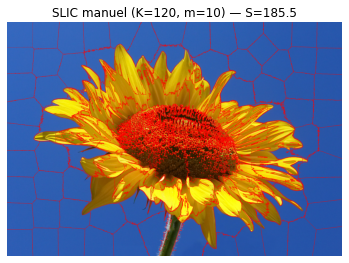

In [51]:
K = 120
m = 10
max_iter = 10

labels, centroids, S = chronometrer(
    slic_manuelle,
    "SLIC manuel complète",
    img,     # image source
    K,           # nombre de superpixels
    m,           # compacité
    max_iter,    # nombre d'itérations
    False,        # enforce_connectivity
    0.25,        # ratio de taille minimale
    True         # assume_rgb
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"SLIC manuel (K={K}, m={m}) — S={S:.1f}")
plt.axis("off")
plt.show()

In [52]:
K_list = [30, 50, 70]
m_list = [8, 14, 20]

resultats = grid_search_slic_manuelle(
    img_rgb = img_rgb,
    K_list = K_list,
    m_list = m_list,
    max_iter = 4,
    assume_rgb = True,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25
)

print("Résultats du grid-search :")
for run in resultats["runs"]:
    print(f"K={run['K']:<4} | m={run['m']:<3} | temps={run['time_s']:.2f}s | "
          f"segments réels={run['n_segments_real']} | S={run['S']:.1f}")

Iteration 1/4
 centroïdes = 531.4639
Iteration 2/4
 centroïdes = 333.4041
Iteration 3/4
 centroïdes = 155.8277
Iteration 4/4
 centroïdes = 106.0096
Iteration 1/4
 centroïdes = 519.3074
Iteration 2/4
 centroïdes = 327.5475
Iteration 3/4
 centroïdes = 127.8909
Iteration 4/4
 centroïdes = 106.6922
Iteration 1/4
 centroïdes = 515.4159
Iteration 2/4
 centroïdes = 319.8685
Iteration 3/4
 centroïdes = 114.5153
Iteration 4/4
 centroïdes = 81.4731
Iteration 1/4
 centroïdes = 470.2629
Iteration 2/4
 centroïdes = 276.3365
Iteration 3/4
 centroïdes = 193.8111
Iteration 4/4
 centroïdes = 170.6838
Iteration 1/4
 centroïdes = 451.8493
Iteration 2/4
 centroïdes = 257.7958
Iteration 3/4
 centroïdes = 176.3808
Iteration 4/4
 centroïdes = 175.1320
Iteration 1/4
 centroïdes = 426.8430
Iteration 2/4
 centroïdes = 216.3923
Iteration 3/4
 centroïdes = 188.6846
Iteration 4/4
 centroïdes = 143.6266
Iteration 1/4
 centroïdes = 442.0865
Iteration 2/4
 centroïdes = 261.5054
Iteration 3/4
 centroïdes = 176.3325
It

In [53]:
best_balanced = min(
    resultats["runs"],
    key=lambda r: (r["time_s"] * 0.3 + abs(r["n_segments_real"] - r["K"]) * 0.7)
)
print("Meilleur compromis :", best_balanced)

Meilleur compromis : {'K': 30, 'm': 14, 'time_s': 5.490620374679565, 'S': 371.0569587902465, 'n_segments_real': 30}


Iteration 1/10
 centroïdes = 519.3074
Iteration 2/10
 centroïdes = 327.5475
Iteration 3/10
 centroïdes = 127.8909
Iteration 4/10
 centroïdes = 106.6922
Iteration 5/10
 centroïdes = 173.0890
Iteration 6/10
 centroïdes = 91.9330
Iteration 7/10
 centroïdes = 104.0292
Iteration 8/10
 centroïdes = 127.1271
Iteration 9/10
 centroïdes = 107.1965
Iteration 10/10
 centroïdes = 91.9196


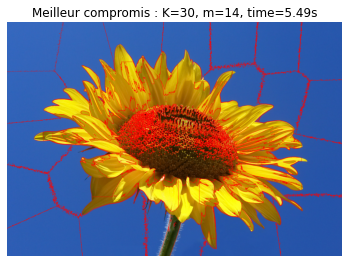

In [54]:
labels, centroids, S = slic_manuelle(
    img_input = img_rgb,
    K = best_balanced['K'],
    m = best_balanced['m'],
    max_iter = 10,
    enforce_connectivity = False,
    connectivity_min_size_ratio = 0.25,
    assume_rgb = True
)

plt.figure(figsize=(6,6))
plt.imshow(mark_boundaries(img_rgb, labels, color=(1,0,0)))
plt.title(f"Meilleur compromis : K={best_balanced['K']}, m={best_balanced['m']}, time={best_balanced['time_s']:.2f}s")
plt.axis("off")
plt.show()

In [72]:
labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels)

Temps d'exécution de enforce_connectivity_fast : 230.24 sec


Temps d'exécution de enforce_connectivity_fast : 63.87 sec
Temps d'exécution de enforce_connectivity_fast : 18.43 sec
Temps d'exécution de enforce_connectivity_fast : 5.35 sec
Temps d'exécution de enforce_connectivity_fast : 2.05 sec
Temps d'exécution de enforce_connectivity_fast : 1.45 sec
Temps d'exécution de enforce_connectivity_fast : 1.46 sec
Temps d'exécution de enforce_connectivity_fast : 1.45 sec
Temps d'exécution de enforce_connectivity_fast : 1.46 sec
Temps d'exécution de enforce_connectivity_fast : 1.45 sec
Temps d'exécution de enforce_connectivity_fast : 1.48 sec
Temps d'exécution de enforce_connectivity_fast : 1.46 sec
Temps d'exécution de enforce_connectivity_fast : 1.47 sec
Temps d'exécution de enforce_connectivity_fast : 1.45 sec
Temps d'exécution de enforce_connectivity_fast : 1.45 sec
Temps d'exécution de enforce_connectivity_fast : 1.45 sec
Temps d'exécution de enforce_connectivity_fast : 1.45 sec
Temps d'exécution de enforce_connectivity_fast : 1.45 sec
Temps d'exéc

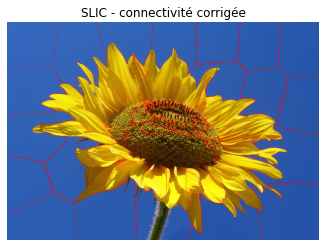

In [73]:
for _ in range(50):
    labels_connected = chronometrer(enforce_connectivity_fast, 
                                "enforce_connectivity_fast", 
                                labels_connected)

img_contours = mark_boundaries(img_rgb, labels_connected, color=(1,0,0)) 

plt.imshow(img_contours)
plt.title("SLIC - connectivité corrigée")
plt.axis('off')
plt.show()

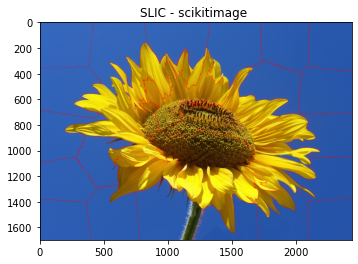

In [74]:
segments = slic(img, n_segments=best_balanced['n_segments_real'], compactness=best_balanced['m'], start_label=0)

img_contour = mark_boundaries(img_rgb, segments, color=(1, 0, 0))  
plt.imshow(img_contour)
plt.title("SLIC - scikitimage ")
plt.show()

La comparaison entre notre implémentation du SLIC et celle proposée par la bibliothèque scikit-image met en évidence des performances globalement similaires en termes de qualité de segmentation.
Bien que la délimitation des superpixels présente de légères variations, la structure générale des images obtenues demeure comparable.

La principale divergence est observée au niveau du centre du tournesol, une zone caractérisée par une forte variabilité de texture et de luminosité. Cette région s’est révélée particulièrement difficile à segmenter : l’algorithme initial ne parvenait pas à produire une partition cohérente.
Ce problème a été atténué grâce à la répétition de la fonction enforce_connectivity lors du post-traitement, permettant ainsi d’améliorer la cohérence spatiale des superpixels et d’éliminer les artefacts de segmentation.

Il convient toutefois de souligner que les résultats obtenus ne peuvent pas être identiques à ceux de scikit-image, en raison de différences fondamentales d’implémentation.
La bibliothèque repose sur une version vectorisée en C, offrant une optimisation bas-niveau des calculs et une réduction significative du temps d’exécution.
De plus, la connectivité des régions y est assurée de manière intégrée au cours du processus de segmentation.
Les centroïdes y sont initialisés à partir d’un calcul de gradient préalablement lissé afin de réduire l’influence du bruit.
Enfin, scikit-image applique automatiquement plusieurs optimisations supplémentaires : suppression des petites régions, re-normalisation des étiquettes et exploitation du multi-threading, contribuant à la fois à la stabilité et à la rapidité du traitement.

Ces différences expliquent les écarts observés en termes de temps de calcul et de résultat final entre notre approche manuelle et celle de la bibliothèque de référence.

# Application de l'algorithme à un exemple concret: SLIC pour l'imagerie médicale
L'imagerie médicale présente souvent des défis spécifiques tels que le bruit, le faible contraste ou des frontières floues entre les tissus. L'utilisation de superpixels via l'algorithme SLIC permet de pré-segmenter l'image en régions homogènes, réduisant ainsi la complexité de l'analyse ultérieure. 

Dans cette section, nous comparons une segmentation basée sur un seuillage simple avec une approche raffinée par SLIC. L'idée est d'utiliser les superpixels pour effectuer un vote majoritaire : si la majorité des pixels d'un superpixel est classée comme "objet d'intérêt" par le seuillage simple, alors tout le superpixel est conservé. Cela permet de lisser les résultats, de combler les trous et d'éliminer les artefacts isolés (bruit poivre et sel).

In [57]:
def segment_slic_vs_noslic(
    path,
    n_segments=200,
    compactness=20,
    sigma=1,
    display=True
):

    #on lit l'image
    img_med = cv2.imread(path)
    if img_med is None:
        raise ValueError(f"Impossible de charger l'image : {path}")
    img_med_rgb = cv2.cvtColor(img_med, cv2.COLOR_BGR2RGB)

    #segmentation SLIC avec scikit
    segments = slic(
        img_med_rgb,
        n_segments=n_segments,
        compactness=compactness,
        sigma=sigma,
        start_label=0
    )

    #on fait la seg sans SLIC
    gray = cv2.cvtColor(img_med_rgb, cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
    mask_no_slic = cv2.morphologyEx(thresh.astype(np.uint8), cv2.MORPH_OPEN, kernel)

    res_no_slic = img_med_rgb.copy()
    res_no_slic[mask_no_slic.astype(bool)] = [255,0,0]

    
    #majority voting; on utilise les superpixels pour lisser la segmentation et éviter le bruit
    labels_slic_clean = np.zeros_like(segments)

    for sp in np.unique(segments):
        region = mask_no_slic[segments == sp]
        majority = 1 if np.sum(region == 1) > np.sum(region == 0) else 0
        labels_slic_clean[segments == sp] = majority

    mask_slic = (labels_slic_clean == 1)

    res_slic = img_med_rgb.copy()
    res_slic[mask_slic] = [255,0,0]

    # affichage
    if display:
        plt.figure(figsize=(6,6))
        plt.imshow(img_med_rgb)
        plt.title("Image originale")
        plt.axis("off")
        plt.show()

        plt.figure(figsize=(6,6))
        plt.imshow(mark_boundaries(img_med_rgb, segments, color=(1,0,0)))
        plt.title(f"SLIC - {n_segments} superpixels")
        plt.axis("off")
        plt.show()

        plt.figure(figsize=(12,6))
        plt.subplot(1,2,1)
        plt.imshow(res_slic)
        plt.title("Segmentation AVEC SLIC")
        plt.axis("off")

        plt.subplot(1,2,2)
        plt.imshow(res_no_slic)
        plt.title("Segmentation SANS SLIC")
        plt.axis("off")

        plt.show()

        print("Pixels détectés SANS SLIC :", np.sum(mask_no_slic))
        print("Pixels détectés AVEC SLIC :", np.sum(mask_slic))
        
    return segments, res_slic, res_no_slic, mask_slic, mask_no_slic

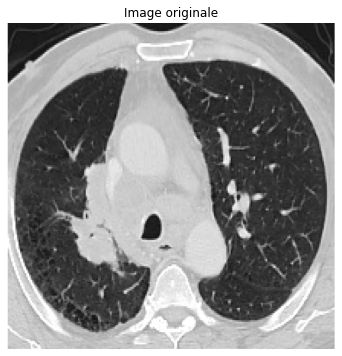

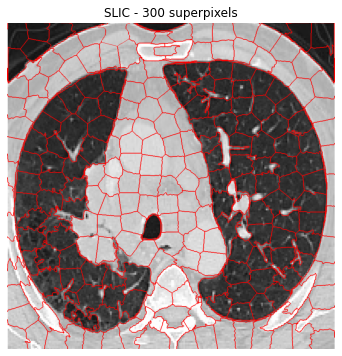

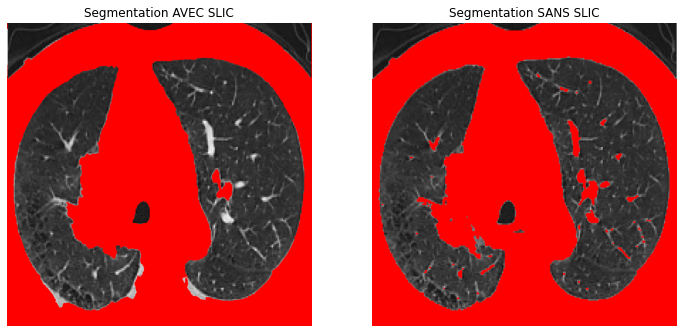

Pixels détectés SANS SLIC : 429256
Pixels détectés AVEC SLIC : 422923


In [58]:
segment_slic_vs_noslic(
    path_images+"poumonA.png",
    n_segments=300,
    compactness=15
)
plt.show()


Sur cette première image de radiographie, on observe que la segmentation sans SLIC est assez bruitée, avec de nombreux petits points isolés détectés à tort comme faisant partie de la zone d'intérêt (les poumons). L'application de SLIC permet de nettoyer ces artefacts en imposant une cohérence régionale. Les poumons sont ainsi mieux délimités, avec des contours plus lisses et moins de "trous" à l'intérieur des zones segmentées. Le résultat est visuellement plus propre et plus exploitable pour une analyse médicale automatisée.
Bien que SLIC réduise le bruit "poivre et sel" visible sur la segmentation brute, le résultat n'est pas parfait.µ

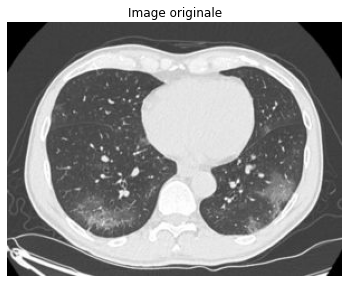

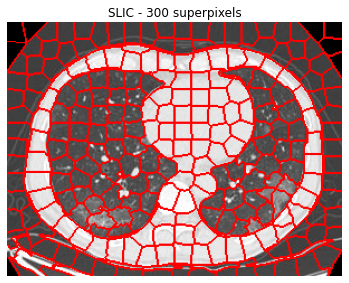

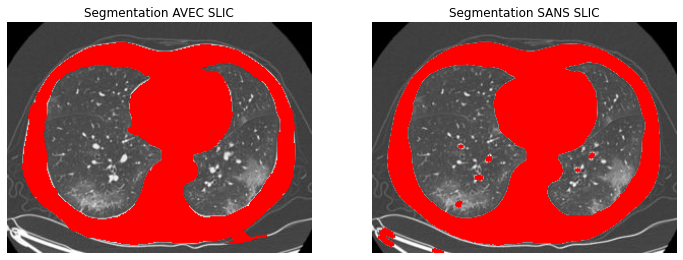

Pixels détectés SANS SLIC : 23778
Pixels détectés AVEC SLIC : 23523


In [59]:
segment_slic_vs_noslic(
    path_images+"poumon2.jpg",
    n_segments=300,
    compactness=15
)
plt.show()

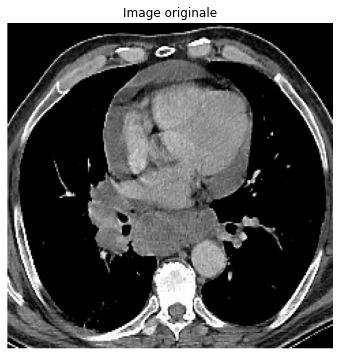

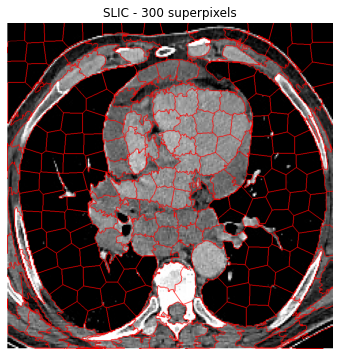

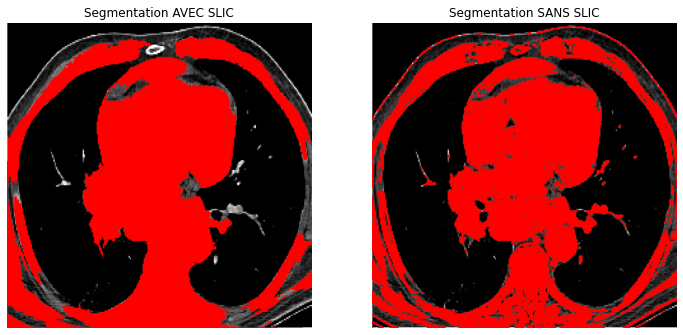

Pixels détectés SANS SLIC : 327513
Pixels détectés AVEC SLIC : 330704


In [60]:
segment_slic_vs_noslic(
    path_images+"poumonB.png",
    n_segments=300,
    compactness=15
)
plt.show()


Ce cas montre clairement l'avantage du lissage par superpixels sur des formes organiques. Les frontières des poumons sont beaucoup plus nettes avec SLIC. Le seuillage simple laisse des bordures irrégulières et déchiquetées, tandis que l'approche par superpixels propose une segmentation qui semble plus anatomiquement plausible, en regroupant les pixels voisins de caractéristiques similaires. Cela démontre la capacité de SLIC à agir comme un régularisateur spatial efficace.


Le résultat semble séduisant par sa propreté, mais il faut rester prudent. La régularisation spatiale imposée par SLIC (avec m) tend à arrondir les formes ou à les rendre plus compactes qu'elles ne le sont. L'algorithme impose sa propre structure géométrique à l'image, ce qui peut introduire un biais dans l'analyse morphologique ultérieure.

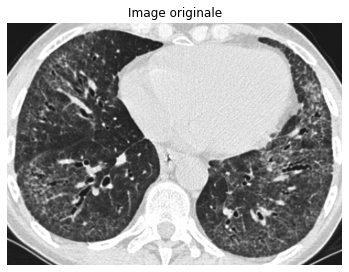

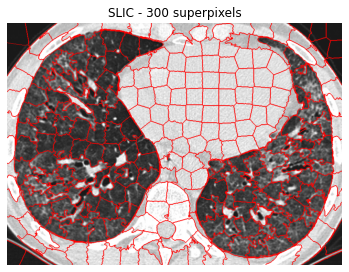

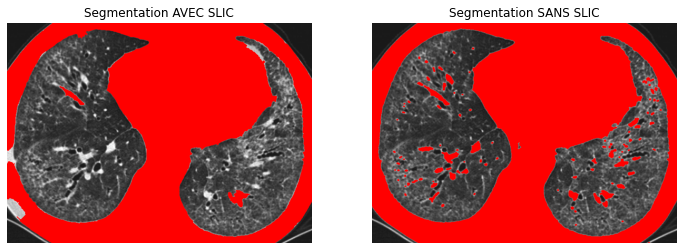

Pixels détectés SANS SLIC : 246589
Pixels détectés AVEC SLIC : 235558


In [61]:
segment_slic_vs_noslic(
    path_images+"poumon4.jpg",
    n_segments=300,
    compactness=15
)
plt.show()


### Conclusion sur l'imagerie médicale

L'intégration de l'algorithme SLIC en amont d'une segmentation par seuillage s'avère très bénéfique pour l'imagerie médicale. Elle agit comme un filtre spatial adaptatif qui :
1.  Réduit le bruit 
2.  Améliore la cohérence des formes détectées, produisant des segmentations plus lisses et plus proches de la réalité anatomique.
3.  Simplifie le traitement en passant d'une analyse pixel par pixel à une analyse région par région.

Bien que le choix des paramètres (nombre de superpixels, compacité) reste crucial pour ne pas effacer de détails fins, cette approche hybride surpasse clairement le seuillage naïf pour la délimitation d'organes et de structures biologiques.

## Application 2

Dans cette application, nous étudions la segmentation d’une scène routière capturée depuis une dashcam. L’objectif est d’identifier différentes régions de l’image (route, marquages, ciel, herbe, objets/voiture) afin de montrer l’intérêt des superpixels dans un contexte réel.
La première approche repose sur une segmentation pixel-par-pixel basée sur des seuils couleurs (HSV et RGB). Cette méthode simple et rapide présente cependant un inconvénient majeur : elle produit une segmentation bruitée, notamment au niveau de la route et des zones texturées.

Pour améliorer la cohérence spatiale du résultat, nous appliquons ensuite un algorithme SLIC (Simple Linear Iterative Clustering). Contrairement à la segmentation brute, SLIC regroupe les pixels en superpixels homogènes et respecte mieux les contours visuels. Dans ce projet, nous utilisons notre propre version manuelle du SLIC, implémentée pendant les séances du TP, puis intégrée comme étape de post-traitement pour lisser les labels initiaux.

Cette application permet ainsi de comparer directement l’effet de SLIC sur une image réelle et d’observer son impact sur la qualité de la segmentation.

In [62]:
def run_application_dashcam(img_path):

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    
    #recherche automatique des meilleurs paramètres SLIC
    K_list = [600, 800, 1000]
    m_list = [8, 12, 16]
    def score_segmentation(labels):
        return np.mean(labels)

    results = []

    for K in K_list:
        for m in m_list:
            labels, _, _ = slic_manuelle(
                img_input=img,
                K=K,
                m=m,
                max_iter=5,       
                enforce_connectivity=False,
                connectivity_min_size_ratio=0.25,
                assume_rgb=True
            )
            s = score_segmentation(labels)
            results.append((K, m, s))

    best_K, best_m, best_score = min(results, key=lambda x: x[2])

    print(f"\nPARAMÈTRES OPTIMISÉS :")
    print(f" K = {best_K}")
    print(f" m = {best_m}")
    print(f" score = {best_score:.2f}")

    #segmentation sans SLIC
    t1 = time.time()

    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    labels_px = np.zeros((h, w), dtype=np.uint8)

    for y in range(h):
        for x in range(w):
            H,S,V = hsv[y,x]
            R,G,B = img[y,x]

            if V>200 and S<40:
                labels_px[y,x] = 1       # route très claire
            elif V<150 and S<40:
                labels_px[y,x] = 0       # zone sombre / bordure
            elif G>R and G>B:
                labels_px[y,x] = 4       # herbe
            elif 80<H<150 and S<80:
                labels_px[y,x] = 3       # ciel
            else:
                labels_px[y,x] = 2       # reste


    t_no_slic = time.time() - t1

    t2 = time.time()

    factor = 0.5
    img_small = cv2.resize(img, None, fx=factor, fy=factor)
    labels_px_small = cv2.resize(labels_px, (img_small.shape[1], img_small.shape[0]),
                                 interpolation=cv2.INTER_NEAREST)

    labels_slic, centroids, S = slic_manuelle(
        img_input=img_small,
        K=best_K,
        m=best_m,
        max_iter=5,
        enforce_connectivity=False,
        connectivity_min_size_ratio=0.25,
        assume_rgb=True
    )

    t_slic = time.time() - t2

    labels_slic_clean = labels_px_small.copy()
    
    for sp in np.unique(labels_slic):
        mask = (labels_slic == sp)
        vals, cnt = np.unique(labels_px_small[mask], return_counts=True)
        labels_slic_clean[mask] = vals[np.argmax(cnt)]

    labels_final = cv2.resize(labels_slic_clean, (w, h), interpolation=cv2.INTER_NEAREST)
    labels_slic_full = cv2.resize(labels_slic, (w, h), interpolation=cv2.INTER_NEAREST)

    #affichage
    plt.figure(figsize=(14,10))

    plt.subplot(2,2,1)
    plt.imshow(img)
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(2,2,2)
    plt.imshow(mark_boundaries(img, labels_slic_full))
    plt.title(f"Contours SLIC (K={best_K}, m={best_m})")
    plt.axis("off")

    plt.subplot(2,2,3)
    plt.imshow(labels_px)
    plt.title("Segmentation SANS SLIC")
    plt.axis("off")

    plt.subplot(2,2,4)
    plt.imshow(labels_final)
    plt.title("Segmentation AVEC SLIC manuel")
    plt.axis("off")

    plt.show()


    
    print(f"SANS SLIC : {t_no_slic:.4f} sec")
    print(f"AVEC SLIC (manuel) : {t_slic:.4f} sec")

    return labels_px, labels_final, t_no_slic, t_slic

Iteration 1/5
 centroïdes = 132.4369
Iteration 2/5
 centroïdes = 78.2308
Iteration 3/5
 centroïdes = 66.4197
Iteration 4/5
 centroïdes = 44.3568
Iteration 5/5
 centroïdes = 36.0148
Iteration 1/5
 centroïdes = 124.3712
Iteration 2/5
 centroïdes = 64.5651
Iteration 3/5
 centroïdes = 53.3909
Iteration 4/5
 centroïdes = 51.4444
Iteration 5/5
 centroïdes = 33.7625
Iteration 1/5
 centroïdes = 120.2121
Iteration 2/5
 centroïdes = 57.4724
Iteration 3/5
 centroïdes = 45.1104
Iteration 4/5
 centroïdes = 40.4703
Iteration 5/5
 centroïdes = 28.8682
Iteration 1/5
 centroïdes = 128.9567
Iteration 2/5
 centroïdes = 72.8471
Iteration 3/5
 centroïdes = 61.7077
Iteration 4/5
 centroïdes = 43.7293
Iteration 5/5
 centroïdes = 33.8785
Iteration 1/5
 centroïdes = 119.1634
Iteration 2/5
 centroïdes = 57.6839
Iteration 3/5
 centroïdes = 50.5207
Iteration 4/5
 centroïdes = 35.6825
Iteration 5/5
 centroïdes = 33.4993
Iteration 1/5
 centroïdes = 115.9882
Iteration 2/5
 centroïdes = 51.4663
Iteration 3/5
 centroï

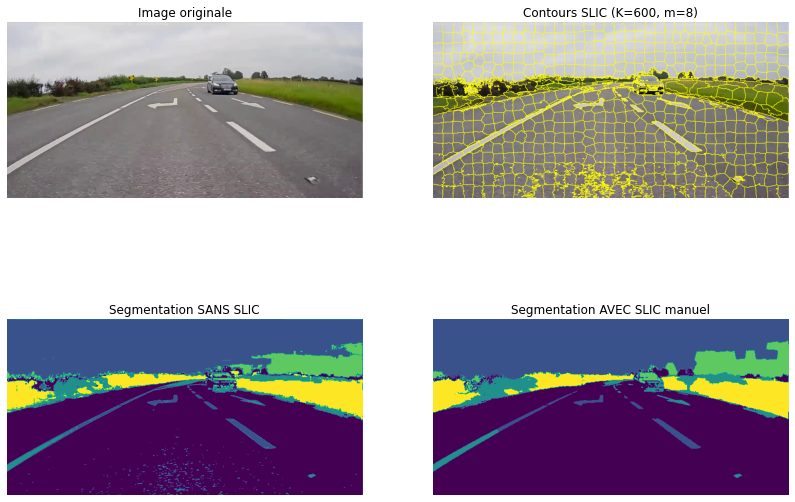

SANS SLIC : 2.8133 sec
AVEC SLIC (manuel) : 2.4911 sec


In [63]:
run_application_dashcam(path_images+"street1.jpg");
plt.show()

**Analyse :**
L'apport de SLIC est indéniable sur l'homogénéité de la route. Là où la segmentation pixel par pixel produisait un résultat bruité (aspect "poivre et sel") dû aux variations de texture du bitume, SLIC lisse ces irrégularités et propose une surface unie et cohérente.
Cependant, cette régularisation a un coût : les détails fins comme les marquages au sol discontinus peuvent être perdus s'ils sont plus fins que la taille des superpixels. De plus, on remarque une sur-segmentation du ciel qui, bien qu'uniforme, est découpé en de multiples polygones, ce qui n'est pas optimal en termes de ressources.

Iteration 1/5
 centroïdes = 88.5010
Iteration 2/5
 centroïdes = 56.6125
Iteration 3/5
 centroïdes = 36.2324
Iteration 4/5
 centroïdes = 28.7777
Iteration 5/5
 centroïdes = 23.3830
Iteration 1/5
 centroïdes = 85.0209
Iteration 2/5
 centroïdes = 41.3751
Iteration 3/5
 centroïdes = 43.3489
Iteration 4/5
 centroïdes = 28.4669
Iteration 5/5
 centroïdes = 21.2207
Iteration 1/5
 centroïdes = 82.4070
Iteration 2/5
 centroïdes = 36.0184
Iteration 3/5
 centroïdes = 45.4895
Iteration 4/5
 centroïdes = 25.0120
Iteration 5/5
 centroïdes = 22.3342
Iteration 1/5
 centroïdes = 89.5887
Iteration 2/5
 centroïdes = 43.3999
Iteration 3/5
 centroïdes = 32.3158
Iteration 4/5
 centroïdes = 24.2084
Iteration 5/5
 centroïdes = 18.6101
Iteration 1/5
 centroïdes = 86.6840
Iteration 2/5
 centroïdes = 34.2666
Iteration 3/5
 centroïdes = 27.3207
Iteration 4/5
 centroïdes = 21.8893
Iteration 5/5
 centroïdes = 18.5309
Iteration 1/5
 centroïdes = 85.8696
Iteration 2/5
 centroïdes = 30.1043
Iteration 3/5
 centroïdes = 

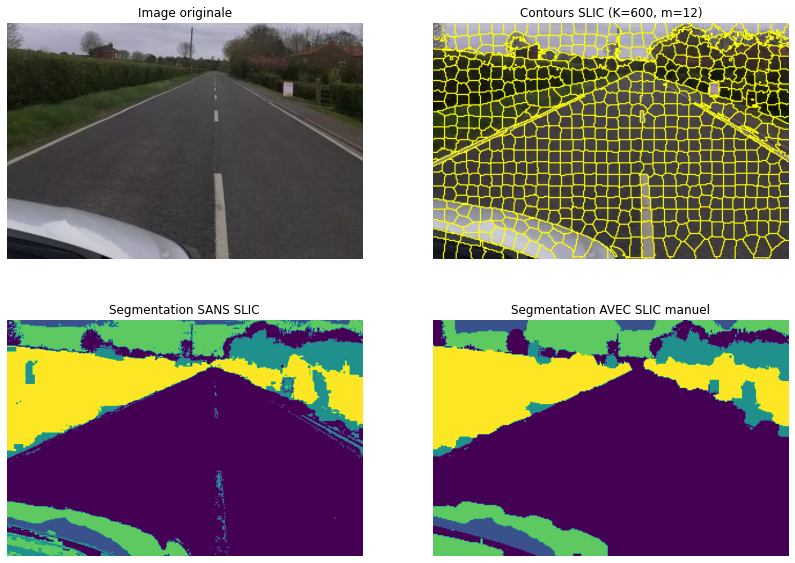

SANS SLIC : 0.9686 sec
AVEC SLIC (manuel) : 0.8284 sec


In [64]:
run_application_dashcam(path_images+"street2.jpeg");
plt.show();

Iteration 1/5
 centroïdes = 139.0735
Iteration 2/5
 centroïdes = 75.8744
Iteration 3/5
 centroïdes = 68.9897
Iteration 4/5
 centroïdes = 44.5435
Iteration 5/5
 centroïdes = 37.1334
Iteration 1/5
 centroïdes = 130.7635
Iteration 2/5
 centroïdes = 60.2727
Iteration 3/5
 centroïdes = 54.6871
Iteration 4/5
 centroïdes = 45.2264
Iteration 5/5
 centroïdes = 37.9692
Iteration 1/5
 centroïdes = 124.9733
Iteration 2/5
 centroïdes = 57.6645
Iteration 3/5
 centroïdes = 47.0292
Iteration 4/5
 centroïdes = 37.7046
Iteration 5/5
 centroïdes = 28.9651
Iteration 1/5
 centroïdes = 141.2781
Iteration 2/5
 centroïdes = 76.3776
Iteration 3/5
 centroïdes = 60.4305
Iteration 4/5
 centroïdes = 42.6366
Iteration 5/5
 centroïdes = 36.3264
Iteration 1/5
 centroïdes = 134.4856
Iteration 2/5
 centroïdes = 63.1768
Iteration 3/5
 centroïdes = 51.6323
Iteration 4/5
 centroïdes = 41.7355
Iteration 5/5
 centroïdes = 31.7419
Iteration 1/5
 centroïdes = 130.8770
Iteration 2/5
 centroïdes = 55.4197
Iteration 3/5
 centroï

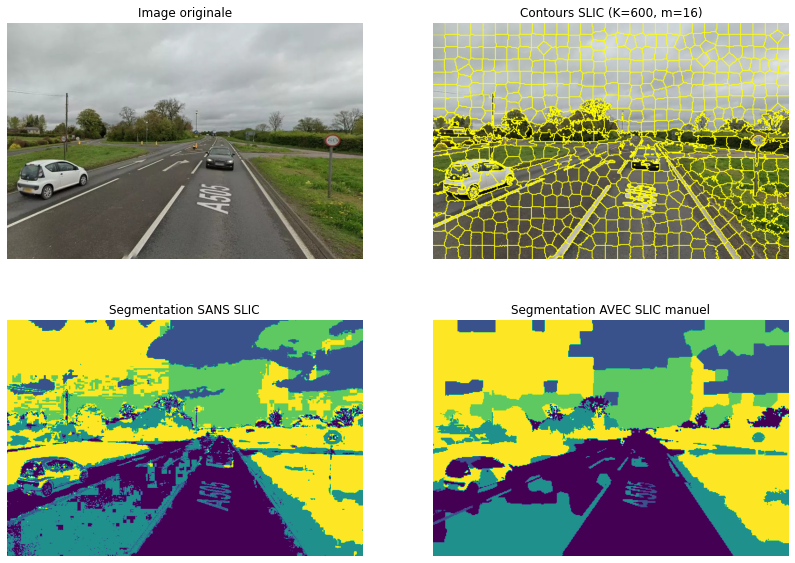

SANS SLIC : 1.6424 sec
AVEC SLIC (manuel) : 1.3963 sec


In [65]:
run_application_dashcam(path_images+"street3.jpg");
plt.show()

La segmentation sur cette image est insatisfaisante : trop de superpixels, contours mal suivis et perte de détails fins. Les paramètres (K, m) ne sont pas adaptés à la complexité de la scène. Il faudrait affiner leur choix ou appliquer un prétraitement pour obtenir une segmentation exploitable.


Iteration 1/5
 centroïdes = 101.2719
Iteration 2/5
 centroïdes = 37.5112
Iteration 3/5
 centroïdes = 26.9592
Iteration 4/5
 centroïdes = 22.3276
Iteration 5/5
 centroïdes = 19.7443
Iteration 1/5
 centroïdes = 100.5838
Iteration 2/5
 centroïdes = 34.5350
Iteration 3/5
 centroïdes = 22.1924
Iteration 4/5
 centroïdes = 16.1434
Iteration 5/5
 centroïdes = 14.7501
Iteration 1/5
 centroïdes = 101.7652
Iteration 2/5
 centroïdes = 33.3181
Iteration 3/5
 centroïdes = 20.9184
Iteration 4/5
 centroïdes = 14.5901
Iteration 5/5
 centroïdes = 10.9254
Iteration 1/5
 centroïdes = 90.5747
Iteration 2/5
 centroïdes = 38.1665
Iteration 3/5
 centroïdes = 43.6005
Iteration 4/5
 centroïdes = 33.1540
Iteration 5/5
 centroïdes = 26.0330
Iteration 1/5
 centroïdes = 90.2764
Iteration 2/5
 centroïdes = 32.9631
Iteration 3/5
 centroïdes = 34.7745
Iteration 4/5
 centroïdes = 21.9052
Iteration 5/5
 centroïdes = 20.1414
Iteration 1/5
 centroïdes = 92.1496
Iteration 2/5
 centroïdes = 29.9045
Iteration 3/5
 centroïdes

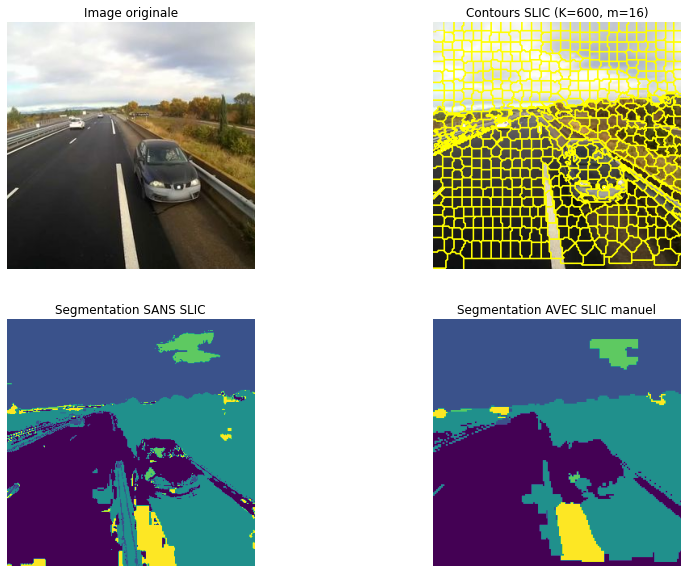

SANS SLIC : 0.3402 sec
AVEC SLIC (manuel) : 0.3676 sec


In [66]:
run_application_dashcam(path_images+"street4.jpeg");
plt.show()

**Analyse :**
Le premier plan est traité avec succès : la route est bien identifiée comme une zone navigable continue, ce qui est l'objectif principal pour une aide à la conduite.
Le bémol vient de la gestion de la perspective. Les superpixels ayant une taille constante, ils deviennent trop grossiers pour les objets situés à l'horizon.

In [67]:
def run_application_dashcam_scikit(path_img):
    import time
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt
    from skimage.segmentation import slic, mark_boundaries

    img = cv2.imread(path_img)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    #sans slic
    t1 = time.time()

    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    labels_px = np.zeros((h,w), dtype=np.uint8)

    for y in range(h):
        for x in range(w):
            H,S,V = hsv[y,x]
            R,G,B = img[y,x]

            if V>200 and S<40:
                labels_px[y,x] = 1       # route très claire
            elif V<150 and S<40:
                labels_px[y,x] = 0       # zone sombre / bordure
            elif G>R and G>B:
                labels_px[y,x] = 4       # herbe
            elif 80<H<150 and S<80:
                labels_px[y,x] = 3       # ciel
            else:
                labels_px[y,x] = 2       # reste

    t_no_slic = time.time() - t1
    print(f"SANS SLIC : {t_no_slic:.4f} sec")

    # slic scikit
    t2 = time.time()

    labels_slic = slic(
        img, 
        n_segments=600,
        compactness=8,
        sigma=1,
        start_label=0
    )

    t_slic = time.time() - t2
    print(f"Temps SLIC (scikit-image) : {t_slic:.4f} sec")

    labels_slic_clean = labels_px.copy()
    for sp in np.unique(labels_slic):
        mask = (labels_slic == sp)
        vals, cnt = np.unique(labels_px[mask], return_counts=True)
        labels_slic_clean[mask] = vals[np.argmax(cnt)]

    # affichage
    plt.figure(figsize=(14,10))

    plt.subplot(2,2,1)
    plt.imshow(img)
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(2,2,2)
    plt.imshow(mark_boundaries(img, labels_slic))
    plt.title("SLIC (scikit-image)")
    plt.axis("off")

    plt.subplot(2,2,3)
    plt.imshow(labels_px)
    plt.title("Segmentation SANS SLIC")
    plt.axis("off")

    plt.subplot(2,2,4)
    plt.imshow(labels_slic_clean)
    plt.title("Segmentation AVEC SLIC (scikit)")
    plt.axis("off")

    plt.show()

    return labels_px, labels_slic_clean, t_no_slic, t_slic

SANS SLIC : 2.8229 sec
Temps SLIC (scikit-image) : 0.5014 sec


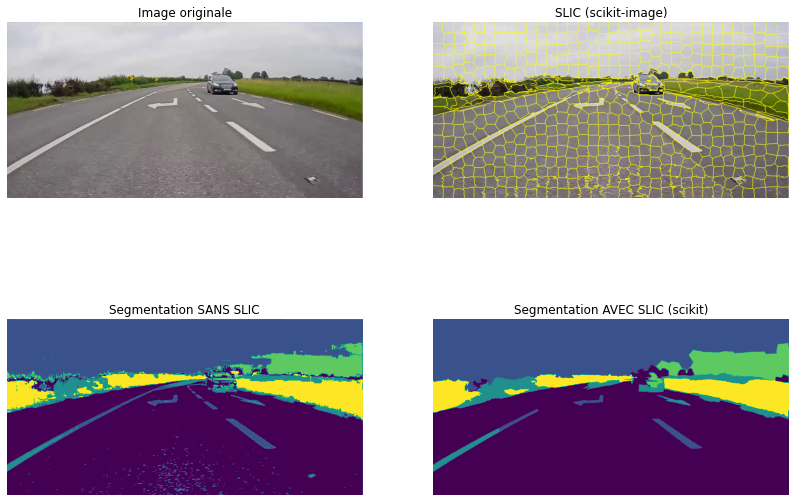

In [68]:
run_application_dashcam_scikit(path_images + "street1.jpg");

SANS SLIC : 0.9751 sec
Temps SLIC (scikit-image) : 0.1616 sec


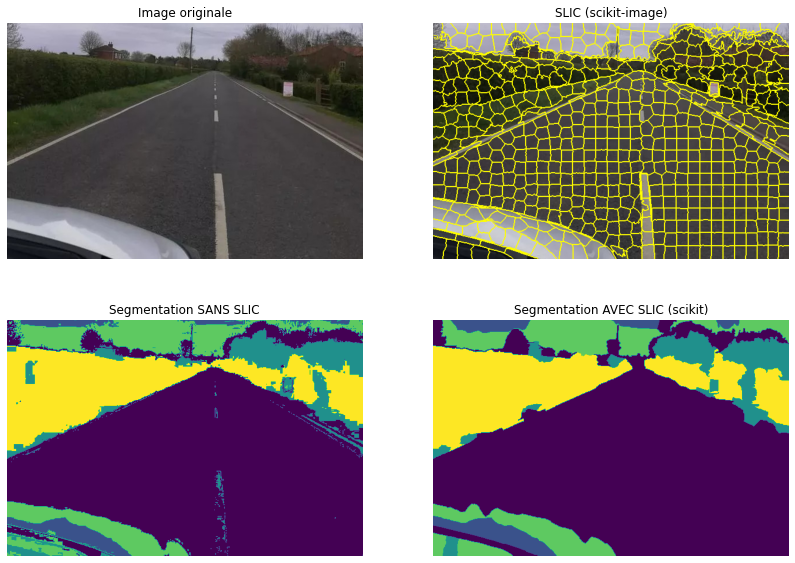

In [69]:
run_application_dashcam_scikit(path_images + "street2.jpeg");

SANS SLIC : 1.6518 sec
Temps SLIC (scikit-image) : 0.2825 sec


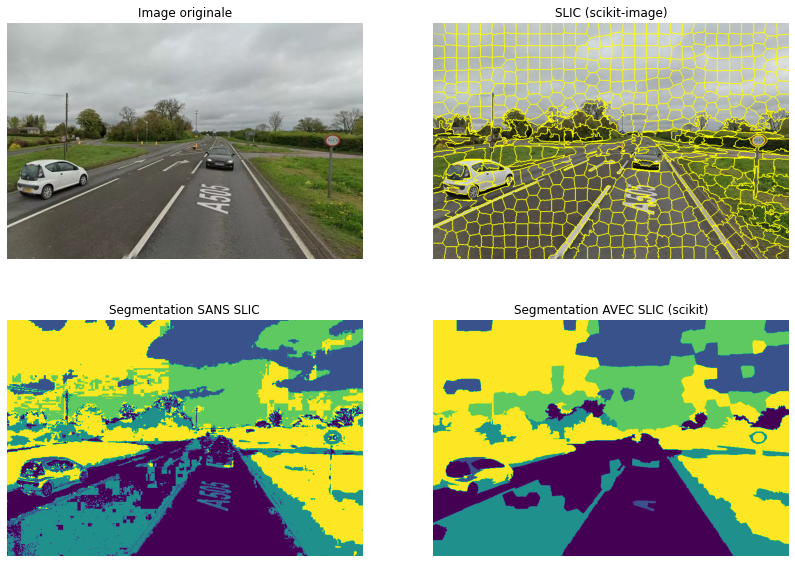

In [70]:
run_application_dashcam_scikit(path_images + "street3.jpg");

SANS SLIC : 0.3370 sec
Temps SLIC (scikit-image) : 0.0646 sec


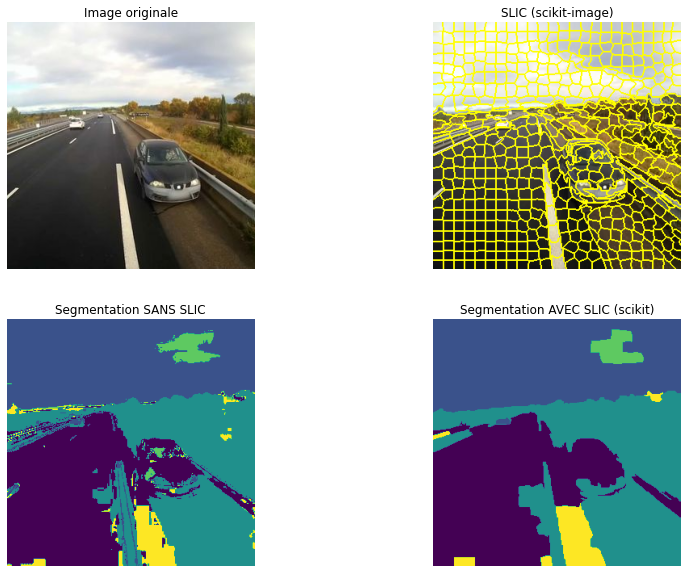

In [71]:
run_application_dashcam_scikit(path_images + "street4.jpeg");

### Conclusion sur la segmentation de scènes routières

L'application de l'algorithme SLIC aux images de dashcam offre un bilan nuancé mais globalement positif pour une étape de pré-traitement :

Points forts :
*   Cohérence spatiale : Il transforme une image bruitée en une mosaïque de régions homogènes, facilitant grandement l'interprétation sémantique (route, ciel, végétation).
*   Réduction de complexité : Il permet de passer de millions de pixels à quelques centaines de superpixels, accélérant les traitements ultérieurs.
*   Robustesse locale : Il lisse efficacement les variations de texture (goudron, herbe) qui piègent les méthodes pixel par pixel.

Limites à considérer :
*   Géométrie rigide : Il peine à préserver les objets fins et allongés (poteaux, lignes blanches) à cause de sa contrainte de compacité.
*   Absence de perspective : Sans adaptation de taille, il dégrade la résolution des objets lointains.
